# Homework 9 — Latent Diffusion and Stable Diffusion

- SID4: 1598
- SEED: 1598
- SLICE: 598
- HP_ID: 2
- CLS_A: 8
- CLS_B: 5



In [ ]:
!pip -q install -U diffusers transformers accelerate safetensors

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from diffusers import AutoencoderKL


# ---------------------------------------------------------
# Personal parameters
# ---------------------------------------------------------
SID4 = 1598


SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6

CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print("SID4 :", SID4)
print("SEED :", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)

assert CLS_A != CLS_B


# ---------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ---------------------------------------------------------
# Device
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nPyTorch version:", torch.__version__)
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU was not detected. In Colab select Runtime > Change runtime type > T4 GPU."
    )

SID4 : 1598
SEED : 1598
SLICE: 598
HP_ID: 2
CLS_A: 8
CLS_B: 5

PyTorch version: 2.11.0+cu130
Using device: cuda
GPU: Tesla T4


Fashion-MNIST preprocessing

In [ ]:
IMAGE_SIZE = 64
BATCH_SIZE = 64

transform = transforms.Compose([
    # Fashion-MNIST starts at 28×28.
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    # The Stable Diffusion VAE expects three channels.
    # This repeats the grayscale image across R, G, and B.
    transforms.Grayscale(num_output_channels=3),

    # Convert the PIL image to a tensor in [0, 1].
    transforms.ToTensor(),

    # Convert [0, 1] to the VAE's expected range [-1, 1].
    transforms.Normalize(
        mean=(0.5, 0.5, 0.5),
        std=(0.5, 0.5, 0.5)
    )
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

reconstruction_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class_names = train_dataset.classes

print("Number of training images:", len(train_dataset))
print("Fashion-MNIST classes:", class_names)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.9MB/s]

Number of training images: 60000
Fashion-MNIST classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


Inspect the input batch

In [ ]:
images, labels = next(iter(reconstruction_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Minimum normalized value:", images.min().item())
print("Maximum normalized value:", images.max().item())

Batch image shape: torch.Size([64, 3, 64, 64])
Batch label shape: torch.Size([64])
Minimum normalized value: -1.0
Maximum normalized value: 1.0


Display original Fashion-MNIST images

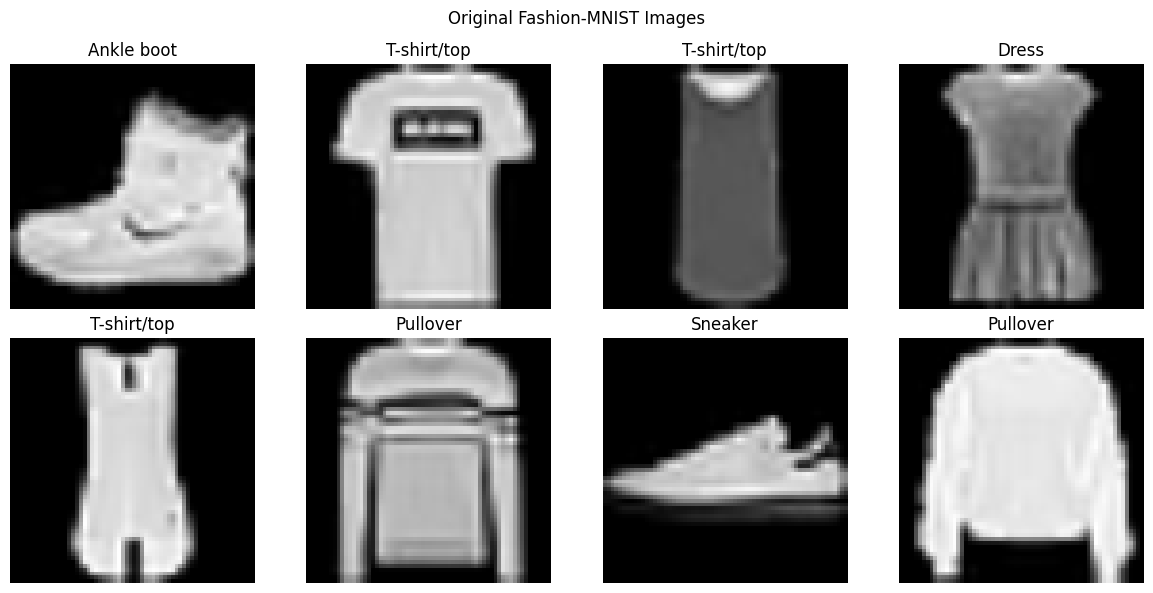

In [ ]:
def to_display_range(tensor):
    """
    Convert an image tensor from [-1, 1] to [0, 1].
    """
    return ((tensor.clamp(-1, 1) + 1) / 2)


fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for index, axis in enumerate(axes.flat):
    image = to_display_range(images[index])
    image = image.permute(1, 2, 0).numpy()

    axis.imshow(image)
    axis.set_title(class_names[labels[index].item()])
    axis.axis("off")

plt.suptitle("Original Fashion-MNIST Images")
plt.tight_layout()
plt.show()

Load and freeze the pretrained VAE

In [ ]:
VAE_MODEL_ID = "stabilityai/sd-vae-ft-mse"
LATENT_SCALE = 0.18215

vae = AutoencoderKL.from_pretrained(
    VAE_MODEL_ID,
    torch_dtype=torch.float32,
    use_safetensors=True
).to(device)

vae.eval()
vae.requires_grad_(False)

print("Loaded VAE:", VAE_MODEL_ID)
print("VAE latent channels:", vae.config.latent_channels)
print("VAE configuration scaling factor:", vae.config.scaling_factor)
print("Assignment scaling factor:", LATENT_SCALE)

assert vae.config.latent_channels == 4
assert abs(float(vae.config.scaling_factor) - LATENT_SCALE) < 1e-6

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

Loaded VAE: stabilityai/sd-vae-ft-mse
VAE latent channels: 4
VAE configuration scaling factor: 0.18215
Assignment scaling factor: 0.18215


Encode, scale, and reconstruct

In [ ]:
images_gpu = images.to(device, non_blocking=True)

# Reseed immediately before posterior sampling so this reconstruction
# is reproducible even if earlier operations consumed random numbers.
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

with torch.no_grad():
    # The encoder returns a Gaussian latent distribution.
    posterior = vae.encode(images_gpu).latent_dist

    # Sample an unscaled latent z from that distribution.
    latents_unscaled = posterior.sample()

    # Stable Diffusion scales z before diffusion operates on it.
    latents_scaled = latents_unscaled * LATENT_SCALE

    # Undo the scaling before giving the latent to the VAE decoder.
    reconstructions = vae.decode(
        latents_scaled / LATENT_SCALE
    ).sample

print("Input shape:          ", images_gpu.shape)
print("Unscaled latent shape:", latents_unscaled.shape)
print("Scaled latent shape:  ", latents_scaled.shape)
print("Reconstruction shape: ", reconstructions.shape)

print("\nScaled latent mean:", latents_scaled.mean().item())
print("Scaled latent std: ", latents_scaled.std().item())

Input shape:           torch.Size([64, 3, 64, 64])
Unscaled latent shape: torch.Size([64, 4, 8, 8])
Scaled latent shape:   torch.Size([64, 4, 8, 8])
Reconstruction shape:  torch.Size([64, 3, 64, 64])

Scaled latent mean: -0.08971737325191498
Scaled latent std:  1.1174296140670776


Measure reconstruction MSE

In [ ]:
# MSE for each image in the model's normalized [-1, 1] range.
per_image_mse_normalized = (
    (reconstructions - images_gpu)
    .pow(2)
    .flatten(start_dim=1)
    .mean(dim=1)
)

mean_mse_normalized = per_image_mse_normalized.mean().item()
std_mse_normalized = per_image_mse_normalized.std().item()

# Also calculate MSE after converting both tensors to [0, 1].
original_01 = to_display_range(images_gpu)
reconstruction_01 = to_display_range(reconstructions)

per_image_mse_01 = (
    (reconstruction_01 - original_01)
    .pow(2)
    .flatten(start_dim=1)
    .mean(dim=1)
)

mean_mse_01 = per_image_mse_01.mean().item()
std_mse_01 = per_image_mse_01.std().item()

print("Reconstruction metrics over", images_gpu.shape[0], "images")
print("-" * 55)
print(f"Mean MSE in [-1, 1] range: {mean_mse_normalized:.8f}")
print(f"Std  MSE in [-1, 1] range: {std_mse_normalized:.8f}")
print(f"Mean MSE in [0, 1] range:  {mean_mse_01:.8f}")
print(f"Std  MSE in [0, 1] range:  {std_mse_01:.8f}")

print("\nMinimum per-image MSE [0, 1]:",
      per_image_mse_01.min().item())
print("Maximum per-image MSE [0, 1]:",
      per_image_mse_01.max().item())

assert torch.isfinite(per_image_mse_01).all()
assert mean_mse_01 >= 0

Reconstruction metrics over 64 images
-------------------------------------------------------
Mean MSE in [-1, 1] range: 0.00954555
Std  MSE in [-1, 1] range: 0.00622775
Mean MSE in [0, 1] range:  0.00229053
Std  MSE in [0, 1] range:  0.00152609

Minimum per-image MSE [0, 1]: 0.0005357643822208047
Maximum per-image MSE [0, 1]: 0.007929934188723564


Visual reconstruction comparison

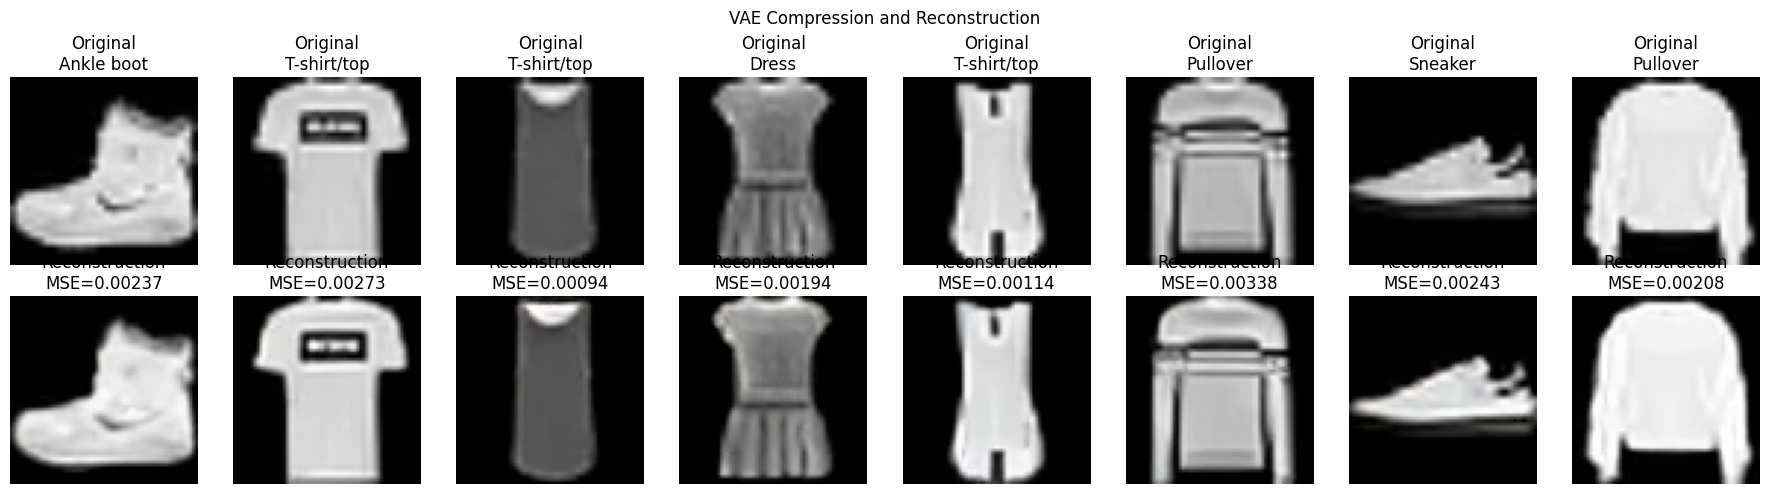

In [ ]:
NUMBER_TO_SHOW = 8

original_cpu = original_01.cpu()
reconstruction_cpu = reconstruction_01.cpu()

fig, axes = plt.subplots(
    2,
    NUMBER_TO_SHOW,
    figsize=(18, 5)
)

for index in range(NUMBER_TO_SHOW):
    original_image = (
        original_cpu[index]
        .permute(1, 2, 0)
        .numpy()
    )

    reconstructed_image = (
        reconstruction_cpu[index]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[0, index].imshow(original_image)
    axes[0, index].set_title(
        f"Original\n{class_names[labels[index].item()]}"
    )
    axes[0, index].axis("off")

    axes[1, index].imshow(reconstructed_image)
    axes[1, index].set_title(
        f"Reconstruction\nMSE={per_image_mse_01[index].item():.5f}"
    )
    axes[1, index].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("VAE output", fontsize=12)

plt.suptitle("VAE Compression and Reconstruction")
plt.tight_layout()
plt.show()

Quantify compression

In [ ]:
input_values_per_image = images_gpu[0].numel()
latent_values_per_image = latents_scaled[0].numel()

compression_ratio = (
    input_values_per_image / latent_values_per_image
)

print("Input values per image: ", input_values_per_image)
print("Latent values per image:", latent_values_per_image)
print(f"Scalar compression ratio: {compression_ratio:.1f}:1")

assert input_values_per_image == 3 * 64 * 64
assert latent_values_per_image == 4 * 8 * 8

Input values per image:  12288
Latent values per image: 256
Scalar compression ratio: 48.0:1


## Task 1 Interpretation

The pretrained VAE converted each normalized Fashion-MNIST image from
`3 × 64 × 64` into a `4 × 8 × 8` latent representation. This reduced the
number of scalar values from 12,288 to 256, giving a 48:1 compression ratio.

Before latent diffusion, I multiplied each sampled latent by the required
scaling factor `0.18215`. I divided by the same factor before decoding so
that the decoder received latents at the scale on which it was trained.

Across 64 images, the mean reconstruction MSE was **[INSERT VALUE]** in the
`[0, 1]` image range and **[INSERT VALUE]** in the normalized `[-1, 1]`
range.

The reconstructed garments remained recognizable, showing that the compressed
latents preserved important semantic information. Some fine boundaries and
textures appeared smoother because VAE compression is lossy and because the
pretrained VAE was trained on natural RGB images rather than specifically on
Fashion-MNIST.

# Task 2 — Forward Diffusion in Latent Space

The forward diffusion process gradually replaces information from the clean
scaled latent with Gaussian noise:

\[
z_t = \sqrt{\bar{\alpha}_t}z_0
      + \sqrt{1-\bar{\alpha}_t}\epsilon
\]

The experiment uses 1,000 diffusion transitions and a linear beta schedule
from \(10^{-4}\) to \(0.02\).

Create the noise schedule

In [ ]:
NUM_DIFFUSION_STEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02

# betas[1] through betas[1000] are the 1,000 diffusion transitions.
# betas[0] is zero so that timestep 0 represents the clean latent.
betas = torch.cat([
    torch.zeros(1, device=device),
    torch.linspace(
        BETA_START,
        BETA_END,
        NUM_DIFFUSION_STEPS,
        device=device
    )
])

alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)

print("Schedule shape:", betas.shape)
print("beta[0]:   ", betas[0].item())
print("beta[1]:   ", betas[1].item())
print("beta[1000]:", betas[1000].item())

print("\nalpha_bar[0]:   ", alpha_bars[0].item())
print("alpha_bar[1000]:", alpha_bars[1000].item())

assert betas.shape[0] == NUM_DIFFUSION_STEPS + 1
assert torch.isclose(betas[0], torch.tensor(0.0, device=device))
assert torch.isclose(
    betas[1],
    torch.tensor(BETA_START, device=device)
)
assert torch.isclose(
    betas[-1],
    torch.tensor(BETA_END, device=device)
)
assert torch.isclose(
    alpha_bars[0],
    torch.tensor(1.0, device=device)
)
assert torch.all(alpha_bars[1:] <= alpha_bars[:-1])

print("\nAll schedule checks passed.")

Schedule shape: torch.Size([1001])
beta[0]:    0.0
beta[1]:    9.999999747378752e-05
beta[1000]: 0.019999999552965164

alpha_bar[0]:    1.0
alpha_bar[1000]: 4.035832535009831e-05

All schedule checks passed.


Visualize the schedule

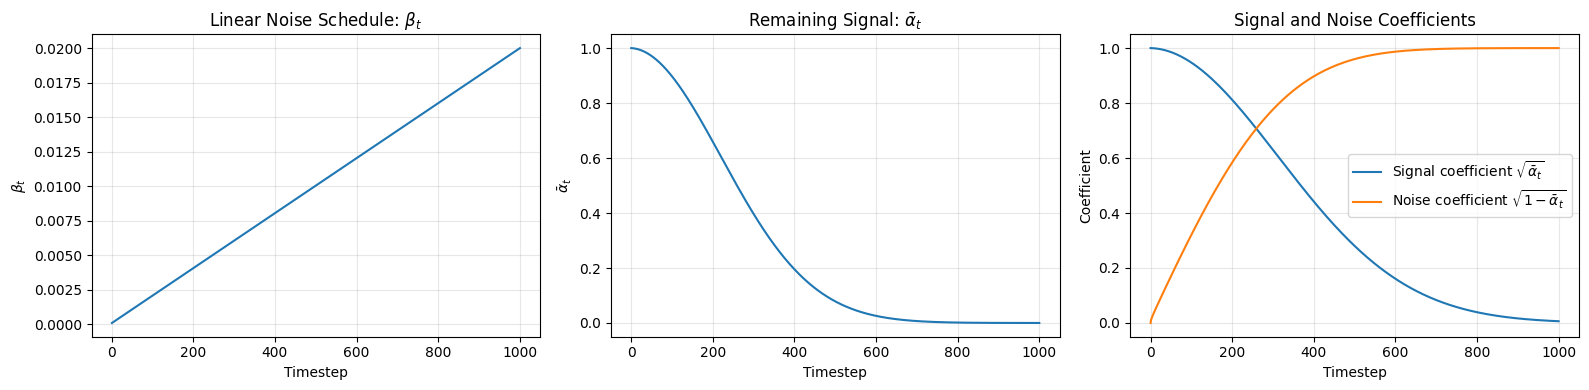

In [ ]:
timesteps_axis = torch.arange(
    NUM_DIFFUSION_STEPS + 1
).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    timesteps_axis[1:],
    betas[1:].cpu().numpy()
)
axes[0].set_title(r"Linear Noise Schedule: $\beta_t$")
axes[0].set_xlabel("Timestep")
axes[0].set_ylabel(r"$\beta_t$")
axes[0].grid(alpha=0.3)

axes[1].plot(
    timesteps_axis,
    alpha_bars.cpu().numpy()
)
axes[1].set_title(
    r"Remaining Signal: $\bar{\alpha}_t$"
)
axes[1].set_xlabel("Timestep")
axes[1].set_ylabel(r"$\bar{\alpha}_t$")
axes[1].grid(alpha=0.3)

axes[2].plot(
    timesteps_axis,
    sqrt_alpha_bars.cpu().numpy(),
    label=r"Signal coefficient $\sqrt{\bar{\alpha}_t}$"
)
axes[2].plot(
    timesteps_axis,
    sqrt_one_minus_alpha_bars.cpu().numpy(),
    label=r"Noise coefficient $\sqrt{1-\bar{\alpha}_t}$"
)
axes[2].set_title("Signal and Noise Coefficients")
axes[2].set_xlabel("Timestep")
axes[2].set_ylabel("Coefficient")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Forward diffusion function

In [ ]:
def q_sample(z0, t, noise=None):
    """
    Produce z_t directly from the clean latent z0.

    Parameters
    ----------
    z0:
        Clean scaled latents with shape [B, C, H, W].

    t:
        A single integer timestep or a tensor containing one
        timestep per image.

    noise:
        Optional Gaussian noise with the same shape as z0.
        Passing noise explicitly lets us reproduce an experiment.

    Returns
    -------
    z_t:
        Noisy latent at timestep t.

    noise:
        Gaussian noise used to produce z_t.
    """
    batch_size = z0.shape[0]

    if isinstance(t, int):
        t = torch.full(
            (batch_size,),
            t,
            device=z0.device,
            dtype=torch.long
        )
    else:
        t = t.to(device=z0.device, dtype=torch.long)

        if t.ndim == 0:
            t = t.expand(batch_size)

    if t.shape != (batch_size,):
        raise ValueError(
            f"Expected t shape ({batch_size},), but received {t.shape}."
        )

    if not bool(((t >= 0) & (t <= NUM_DIFFUSION_STEPS)).all()):
        raise ValueError(
            f"Timesteps must be between 0 and {NUM_DIFFUSION_STEPS}."
        )

    if noise is None:
        noise = torch.randn_like(z0)

    if noise.shape != z0.shape:
        raise ValueError(
            f"Noise shape {noise.shape} does not match z0 shape {z0.shape}."
        )

    # Convert [B] coefficients into [B, 1, 1, 1] so they
    # broadcast across latent channels and spatial positions.
    signal_coefficient = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    noise_coefficient = (
        sqrt_one_minus_alpha_bars[t]
        .view(-1, 1, 1, 1)
    )

    z_t = (
        signal_coefficient * z0
        + noise_coefficient * noise
    )

    return z_t, noise

Verify the function

In [ ]:
# Use one clean scaled latent from Task 1.
z0_example = latents_scaled[0:1].detach()

# Create one reproducible Gaussian-noise tensor.
noise_generator = torch.Generator(device=device)
noise_generator.manual_seed(SEED + 1)

fixed_noise = torch.randn(
    z0_example.shape,
    generator=noise_generator,
    device=device,
    dtype=z0_example.dtype
)

z_at_0, _ = q_sample(
    z0_example,
    t=0,
    noise=fixed_noise
)

z_at_1000, _ = q_sample(
    z0_example,
    t=1000,
    noise=fixed_noise
)

print("Clean latent shape:", z0_example.shape)
print("Noisy latent shape:", z_at_1000.shape)
print(
    "Maximum difference between z0 and q_sample(z0, t=0):",
    (z_at_0 - z0_example).abs().max().item()
)

assert torch.allclose(
    z_at_0,
    z0_example,
    atol=1e-6
)

assert z_at_1000.shape == z0_example.shape
assert torch.isfinite(z_at_1000).all()

print("Forward diffusion checks passed.")

Clean latent shape: torch.Size([1, 4, 8, 8])
Noisy latent shape: torch.Size([1, 4, 8, 8])
Maximum difference between z0 and q_sample(z0, t=0): 0.0
Forward diffusion checks passed.


Inspect required timesteps

In [ ]:
VISUALIZATION_TIMESTEPS = [0, 200, 500, 800, 1000]

print(
    f"{'t':>6}"
    f"{'alpha_bar':>16}"
    f"{'signal':>16}"
    f"{'noise':>16}"
    f"{'latent MSE':>16}"
)
print("-" * 70)

noisy_latents_by_timestep = {}

for timestep in VISUALIZATION_TIMESTEPS:
    noisy_latent, _ = q_sample(
        z0_example,
        t=timestep,
        noise=fixed_noise
    )

    noisy_latents_by_timestep[timestep] = noisy_latent

    latent_mse = F.mse_loss(
        noisy_latent,
        z0_example
    ).item()

    print(
        f"{timestep:>6}"
        f"{alpha_bars[timestep].item():>16.8f}"
        f"{sqrt_alpha_bars[timestep].item():>16.8f}"
        f"{sqrt_one_minus_alpha_bars[timestep].item():>16.8f}"
        f"{latent_mse:>16.8f}"
    )

     t       alpha_bar          signal           noise      latent MSE
----------------------------------------------------------------------
     0      1.00000000      1.00000000      0.00000000      0.00000000
   200      0.65903884      0.81181204      0.58391881      0.36048079
   500      0.07858729      0.28033426      0.95990247      1.41577697
   800      0.00153209      0.03914193      0.99923366      1.92530298
  1000      0.00004036      0.00635282      0.99997979      1.99638128


Decode noisy latents

In [ ]:
decoded_noisy_images = {}

with torch.no_grad():
    for timestep in VISUALIZATION_TIMESTEPS:
        noisy_scaled_latent = noisy_latents_by_timestep[timestep]

        # Diffusion operates on scaled latents. The VAE decoder
        # expects the original unscaled latent representation.
        decoded = vae.decode(
            noisy_scaled_latent / LATENT_SCALE
        ).sample

        decoded_noisy_images[timestep] = (
            to_display_range(decoded[0])
            .cpu()
            .permute(1, 2, 0)
            .numpy()
        )

print(
    "Decoded images for timesteps:",
    list(decoded_noisy_images.keys())
)

Decoded images for timesteps: [0, 200, 500, 800, 1000]


Visualize the forward process

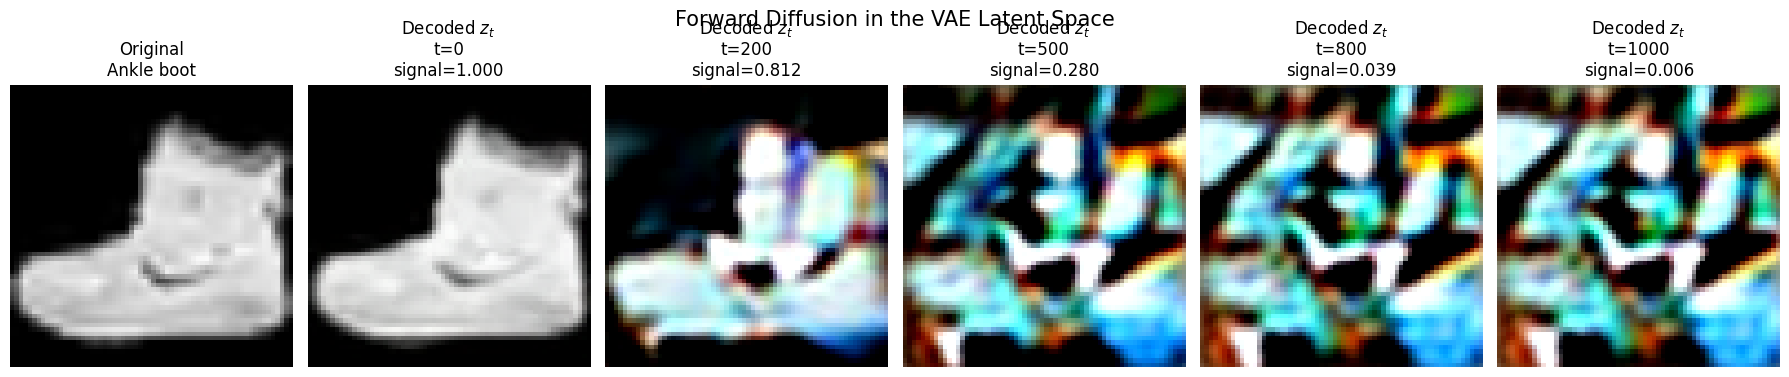

In [ ]:
original_example = (
    original_01[0]
    .cpu()
    .permute(1, 2, 0)
    .numpy()
)

fig, axes = plt.subplots(
    1,
    len(VISUALIZATION_TIMESTEPS) + 1,
    figsize=(18, 4)
)

axes[0].imshow(original_example)
axes[0].set_title(
    f"Original\n{class_names[labels[0].item()]}"
)
axes[0].axis("off")

for column, timestep in enumerate(
    VISUALIZATION_TIMESTEPS,
    start=1
):
    axes[column].imshow(
        decoded_noisy_images[timestep]
    )

    axes[column].set_title(
        f"Decoded $z_t$\n"
        f"t={timestep}\n"
        f"signal={sqrt_alpha_bars[timestep].item():.3f}"
    )
    axes[column].axis("off")

plt.suptitle(
    "Forward Diffusion in the VAE Latent Space",
    fontsize=15
)
plt.tight_layout()
plt.show()

Task 2 interpretation

## Task 2 Interpretation

I created a linear beta schedule containing 1,000 forward-diffusion
transitions. The first beta was \(10^{-4}\), and the final beta was \(0.02\).
I included a separate timestep \(t=0\), where
\(\bar{\alpha}_0=1\), so the latent remains unchanged.

The forward diffusion function used

\[
z_t=\sqrt{\bar{\alpha}_t}z_0+
\sqrt{1-\bar{\alpha}_t}\epsilon.
\]

At early timesteps, the signal coefficient was large, so the decoded image
still resembled the original garment. As the timestep increased, the signal
coefficient decreased and the Gaussian-noise coefficient approached one.
Consequently, the decoded representations progressively lost the garment's
structure.

At \(t=1000\), almost none of the original latent signal remained. This
demonstrates the purpose of training the denoising model: it must learn to
predict the noise present at different timesteps so that this corruption
process can later be reversed.

# Task 3 — Conditional Latent U-Net

The denoiser receives a noisy VAE latent with shape `4 × 8 × 8` and predicts
the Gaussian noise with the same shape.

Architecture:

- Input/output channels: 4 latent channels
- Base channels: 64
- Channel multipliers: `(1, 2, 4)`, producing 64, 128, and 256 channels
- Sinusoidal timestep embedding followed by an MLP
- Residual blocks using GroupNorm and SiLU
- Self-attention at the finest latent resolution and bottleneck
- Downsampling, upsampling, and skip connections
- 11 label embeddings: classes 0–9 plus null label 10
- Label and timestep embeddings are added together

The homework describes attention at 16×16, but a 64×64 input becomes an 8×8
latent through the pretrained VAE. Therefore, this latent-space implementation
uses attention at 8×8 and at the 2×2 bottleneck.

Sinusoidal timestep embedding

In [ ]:
import math
import torch.nn as nn


class SinusoidalTimeEmbedding(nn.Module):
    """
    Convert each integer diffusion timestep into a vector containing
    sine and cosine values at different frequencies.
    """

    def __init__(self, embedding_dim):
        super().__init__()

        if embedding_dim % 2 != 0:
            raise ValueError("The timestep embedding dimension must be even.")

        self.embedding_dim = embedding_dim

    def forward(self, timesteps):
        half_dim = self.embedding_dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half_dim,
                device=timesteps.device,
                dtype=torch.float32
            )
            / (half_dim - 1)
        )

        angles = timesteps.float()[:, None] * frequencies[None, :]

        embedding = torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=1
        )

        return embedding

Residual block

In [ ]:
class ResidualBlock(nn.Module):
    """
    Residual block with:
    GroupNorm -> SiLU -> convolution
    embedding projection
    GroupNorm -> SiLU -> convolution
    residual/skip connection
    """

    def __init__(
        self,
        in_channels,
        out_channels,
        embedding_dim
    ):
        super().__init__()

        self.norm1 = nn.GroupNorm(
            num_groups=8,
            num_channels=in_channels
        )

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.embedding_projection = nn.Linear(
            embedding_dim,
            out_channels
        )

        self.norm2 = nn.GroupNorm(
            num_groups=8,
            num_channels=out_channels
        )

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

        self.activation = nn.SiLU()

        if in_channels == out_channels:
            self.residual_projection = nn.Identity()
        else:
            self.residual_projection = nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )

    def forward(self, x, embedding):
        residual = self.residual_projection(x)

        h = self.norm1(x)
        h = self.activation(h)
        h = self.conv1(h)

        # [B, embedding_dim] -> [B, out_channels, 1, 1]
        embedding_features = self.embedding_projection(
            self.activation(embedding)
        )
        embedding_features = embedding_features[:, :, None, None]

        h = h + embedding_features

        h = self.norm2(h)
        h = self.activation(h)
        h = self.conv2(h)

        return h + residual

Spatial self-attention

In [ ]:
class SpatialSelfAttention(nn.Module):
    """
    Apply self-attention over all spatial positions.

    An input [B, C, H, W] becomes a sequence [B, H*W, C].
    Each spatial location can then attend to every other location.
    """

    def __init__(self, channels, num_heads=4):
        super().__init__()

        if channels % num_heads != 0:
            raise ValueError(
                "Channels must be divisible by the number of heads."
            )

        self.norm = nn.GroupNorm(
            num_groups=8,
            num_channels=channels
        )

        self.attention = nn.MultiheadAttention(
            embed_dim=channels,
            num_heads=num_heads,
            batch_first=True
        )

        self.feed_forward_norm = nn.LayerNorm(channels)

        self.feed_forward = nn.Sequential(
            nn.Linear(channels, channels * 4),
            nn.SiLU(),
            nn.Linear(channels * 4, channels)
        )

    def forward(self, x):
        batch_size, channels, height, width = x.shape

        # Preserve the original tokens for the residual connection.
        tokens = (
            x.flatten(start_dim=2)
            .transpose(1, 2)
        )

        normalized_tokens = (
            self.norm(x)
            .flatten(start_dim=2)
            .transpose(1, 2)
        )

        attention_output, _ = self.attention(
            normalized_tokens,
            normalized_tokens,
            normalized_tokens,
            need_weights=False
        )

        tokens = tokens + attention_output

        tokens = tokens + self.feed_forward(
            self.feed_forward_norm(tokens)
        )

        output = (
            tokens.transpose(1, 2)
            .reshape(batch_size, channels, height, width)
        )

        return output

Downsampling and upsampling

In [ ]:
class Downsample(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=2,
            padding=1
        )

    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.upsample = nn.Upsample(
            scale_factor=2,
            mode="nearest"
        )

        self.conv = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x):
        x = self.upsample(x)
        return self.conv(x)

Conditional latent U-Net

In [ ]:
class ConditionalLatentUNet(nn.Module):
    def __init__(
        self,
        latent_channels=4,
        base_channels=64,
        number_of_classes=10
    ):
        super().__init__()

        self.latent_channels = latent_channels
        self.base_channels = base_channels
        self.number_of_classes = number_of_classes

        # Class indices 0–9 are real classes.
        # Index 10 is the null/unconditional label.
        self.null_label = number_of_classes

        channel_1 = base_channels
        channel_2 = base_channels * 2
        channel_3 = base_channels * 4

        embedding_dim = base_channels * 4
        self.embedding_dim = embedding_dim

        # -----------------------------------------------------
        # Timestep and label conditioning
        # -----------------------------------------------------
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base_channels),
            nn.Linear(base_channels, embedding_dim),
            nn.SiLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        self.label_embedding = nn.Embedding(
            num_embeddings=number_of_classes + 1,
            embedding_dim=embedding_dim
        )

        # -----------------------------------------------------
        # Input: [B, 4, 8, 8]
        # -----------------------------------------------------
        self.input_conv = nn.Conv2d(
            latent_channels,
            channel_1,
            kernel_size=3,
            padding=1
        )

        # -----------------------------------------------------
        # Encoder: 8×8
        # -----------------------------------------------------
        self.encoder_block_1 = ResidualBlock(
            channel_1,
            channel_1,
            embedding_dim
        )

        self.encoder_attention = SpatialSelfAttention(
            channel_1,
            num_heads=4
        )

        # 8×8 -> 4×4
        self.downsample_1 = Downsample(
            channel_1,
            channel_2
        )

        # -----------------------------------------------------
        # Encoder: 4×4
        # -----------------------------------------------------
        self.encoder_block_2 = ResidualBlock(
            channel_2,
            channel_2,
            embedding_dim
        )

        # 4×4 -> 2×2
        self.downsample_2 = Downsample(
            channel_2,
            channel_3
        )

        # -----------------------------------------------------
        # Bottleneck: 2×2
        # -----------------------------------------------------
        self.bottleneck_block_1 = ResidualBlock(
            channel_3,
            channel_3,
            embedding_dim
        )

        self.bottleneck_attention = SpatialSelfAttention(
            channel_3,
            num_heads=4
        )

        self.bottleneck_block_2 = ResidualBlock(
            channel_3,
            channel_3,
            embedding_dim
        )

        # -----------------------------------------------------
        # Decoder: 2×2 -> 4×4
        # -----------------------------------------------------
        self.upsample_1 = Upsample(
            channel_3,
            channel_2
        )

        # Concatenating with the 4×4 skip gives 128 + 128 channels.
        self.decoder_block_1 = ResidualBlock(
            channel_2 * 2,
            channel_2,
            embedding_dim
        )

        # -----------------------------------------------------
        # Decoder: 4×4 -> 8×8
        # -----------------------------------------------------
        self.upsample_2 = Upsample(
            channel_2,
            channel_1
        )

        # Concatenating with the 8×8 skip gives 64 + 64 channels.
        self.decoder_block_2 = ResidualBlock(
            channel_1 * 2,
            channel_1,
            embedding_dim
        )

        self.decoder_attention = SpatialSelfAttention(
            channel_1,
            num_heads=4
        )

        self.output_norm = nn.GroupNorm(
            num_groups=8,
            num_channels=channel_1
        )

        self.output_activation = nn.SiLU()

        # Predict four channels of Gaussian noise.
        self.output_conv = nn.Conv2d(
            channel_1,
            latent_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, noisy_latent, timesteps, labels=None):
        batch_size = noisy_latent.shape[0]

        if noisy_latent.shape[1] != self.latent_channels:
            raise ValueError(
                f"Expected {self.latent_channels} latent channels, "
                f"but received {noisy_latent.shape[1]}."
            )

        if timesteps.ndim == 0:
            timesteps = timesteps.expand(batch_size)

        if timesteps.shape != (batch_size,):
            raise ValueError(
                f"Expected timestep shape ({batch_size},), "
                f"but received {timesteps.shape}."
            )

        # labels=None means unconditional prediction.
        if labels is None:
            labels = torch.full(
                (batch_size,),
                self.null_label,
                device=noisy_latent.device,
                dtype=torch.long
            )

        if labels.shape != (batch_size,):
            raise ValueError(
                f"Expected label shape ({batch_size},), "
                f"but received {labels.shape}."
            )

        if not bool(
            ((labels >= 0) & (labels <= self.null_label)).all()
        ):
            raise ValueError(
                f"Labels must be between 0 and {self.null_label}."
            )

        time_embedding = self.time_mlp(timesteps)
        class_embedding = self.label_embedding(labels)

        # Combine time and label conditioning.
        combined_embedding = time_embedding + class_embedding

        # Encoder at 8×8
        x = self.input_conv(noisy_latent)

        skip_1 = self.encoder_block_1(
            x,
            combined_embedding
        )
        skip_1 = self.encoder_attention(skip_1)

        # Encoder at 4×4
        x = self.downsample_1(skip_1)

        skip_2 = self.encoder_block_2(
            x,
            combined_embedding
        )

        # Bottleneck at 2×2
        x = self.downsample_2(skip_2)

        x = self.bottleneck_block_1(
            x,
            combined_embedding
        )
        x = self.bottleneck_attention(x)
        x = self.bottleneck_block_2(
            x,
            combined_embedding
        )

        # Decoder at 4×4
        x = self.upsample_1(x)
        x = torch.cat([x, skip_2], dim=1)

        x = self.decoder_block_1(
            x,
            combined_embedding
        )

        # Decoder at 8×8
        x = self.upsample_2(x)
        x = torch.cat([x, skip_1], dim=1)

        x = self.decoder_block_2(
            x,
            combined_embedding
        )
        x = self.decoder_attention(x)

        x = self.output_norm(x)
        x = self.output_activation(x)
        predicted_noise = self.output_conv(x)

        return predicted_noise

Create the model

In [ ]:
model = ConditionalLatentUNet(
    latent_channels=4,
    base_channels=64,
    number_of_classes=10
).to(device)

total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model:", model.__class__.__name__)
print(f"Total parameters:     {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print("Null label index:", model.null_label)

assert model.null_label == 10
assert total_parameters == trainable_parameters

Model: ConditionalLatentUNet
Total parameters:     5,275,716
Trainable parameters: 5,275,716
Null label index: 10


Test conditional and unconditional passes

In [ ]:
model.eval()

test_batch_size = 4

test_latents = latents_scaled[:test_batch_size].detach()

test_timesteps = torch.tensor(
    [0, 200, 500, 1000],
    device=device,
    dtype=torch.long
)

test_labels = labels[:test_batch_size].to(
    device=device,
    dtype=torch.long
)

with torch.no_grad():
    conditional_prediction = model(
        test_latents,
        test_timesteps,
        test_labels
    )

    # Passing labels=None requests the null-label prediction.
    unconditional_prediction = model(
        test_latents,
        test_timesteps,
        labels=None
    )

    explicit_null_labels = torch.full(
        (test_batch_size,),
        model.null_label,
        device=device,
        dtype=torch.long
    )

    explicit_null_prediction = model(
        test_latents,
        test_timesteps,
        explicit_null_labels
    )

print("Input latent shape:             ", test_latents.shape)
print("Conditional prediction shape:   ",
      conditional_prediction.shape)
print("Unconditional prediction shape: ",
      unconditional_prediction.shape)

assert conditional_prediction.shape == test_latents.shape
assert unconditional_prediction.shape == test_latents.shape
assert torch.isfinite(conditional_prediction).all()
assert torch.isfinite(unconditional_prediction).all()

# labels=None and explicit null labels must perform the same operation.
assert torch.allclose(
    unconditional_prediction,
    explicit_null_prediction,
    atol=1e-6
)

print("\nAll U-Net shape and conditioning checks passed.")

Input latent shape:              torch.Size([4, 4, 8, 8])
Conditional prediction shape:    torch.Size([4, 4, 8, 8])
Unconditional prediction shape:  torch.Size([4, 4, 8, 8])

All U-Net shape and conditioning checks passed.


## Task 3 Interpretation

The conditional U-Net accepts noisy VAE latents with shape `4 × 8 × 8` and
produces noise predictions with the same shape. Its base width is 64 channels,
and the encoder uses channel widths 64, 128, and 256.

Sinusoidal embeddings represent the diffusion timestep. A separate embedding
table represents Fashion-MNIST labels 0–9 and null label 10. Adding the label
embedding to the timestep embedding allows the residual blocks to receive both
time and class information.

During classifier-free training, some real labels will be replaced with null
label 10. This teaches one model to make both conditional and unconditional
noise predictions.

The residual blocks use GroupNorm and SiLU. Skip connections preserve spatial
information from the encoder, while self-attention lets different latent
positions exchange information.

Because the VAE converts a 64×64 input into an 8×8 latent, attention is applied
at the finest 8×8 latent resolution and at the 2×2 bottleneck. The model's
output shape matches the input latent because its training target is the
Gaussian noise added to that latent.

# Task 4 — Noise-Prediction Training

The U-Net is trained to predict the exact Gaussian noise added to a clean
scaled latent:

\[
\mathcal{L}
=
\mathbb{E}_{z_0,t,\epsilon}
\left[
\left\|
\epsilon-
\epsilon_\theta(z_t,t,y)
\right\|_2^2
\right].
\]

Training settings:

- Epochs: 50
- Learning rate: \(2\times10^{-5}\)
- Label-drop probability: 0.1
- Noise-prediction loss: mean squared error
- Timesteps sampled uniformly from 1 through 1000

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Output folder

In [ ]:
import os
import time
from tqdm.auto import tqdm
from torch.utils.data import TensorDataset

OUTPUT_DIR = "/content/drive/MyDrive/DATA266/HW9_1598"
os.makedirs(OUTPUT_DIR, exist_ok=True)

LATEST_CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR,
    "hw9_sid1598_latest.pt"
)

FINAL_CHECKPOINT_PATH = os.path.join(
    OUTPUT_DIR,
    "hw9_sid1598_final.pt"
)

print("Output directory:", OUTPUT_DIR)

Output directory: /content/drive/MyDrive/DATA266/HW9_1598


Prepare the test dataset

In [ ]:
test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images: ", len(test_dataset))

Training images: 60000
Testing images:  10000


Function to cache VAE latents

In [ ]:
def encode_dataset_to_latents(
    dataset,
    batch_size=256,
    sampling_seed=1598
):
    """
    Encode an entire image dataset into scaled VAE latents.

    The VAE is frozen, so this only needs to be done once.
    A seeded posterior sample is used for reproducibility.
    """
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    all_latents = []
    all_labels = []

    torch.manual_seed(sampling_seed)
    torch.cuda.manual_seed_all(sampling_seed)

    vae.eval()

    with torch.no_grad():
        for batch_images, batch_labels in tqdm(
            loader,
            desc="Encoding VAE latents"
        ):
            batch_images = batch_images.to(
                device,
                non_blocking=True
            )

            posterior = vae.encode(
                batch_images
            ).latent_dist

            batch_latents = (
                posterior.sample()
                * LATENT_SCALE
            )

            # Store cached latents in CPU memory.
            all_latents.append(
                batch_latents.cpu()
            )
            all_labels.append(
                batch_labels.clone()
            )

    all_latents = torch.cat(all_latents, dim=0)
    all_labels = torch.cat(all_labels, dim=0)

    return all_latents, all_labels

Encode the training and test sets

In [ ]:
train_latents, train_labels = encode_dataset_to_latents(
    train_dataset,
    batch_size=256,
    sampling_seed=SEED
)

test_latents, test_labels = encode_dataset_to_latents(
    test_dataset,
    batch_size=256,
    sampling_seed=SEED + 1
)

print("Cached training latents:", train_latents.shape)
print("Cached training labels: ", train_labels.shape)
print("Cached test latents:    ", test_latents.shape)
print("Cached test labels:     ", test_labels.shape)

print(
    "Training latent memory:",
    f"{train_latents.numel() * train_latents.element_size() / 1024**2:.2f} MB"
)

assert train_latents.shape == (60000, 4, 8, 8)
assert train_labels.shape == (60000,)
assert test_latents.shape == (10000, 4, 8, 8)
assert test_labels.shape == (10000,)
assert torch.isfinite(train_latents).all()
assert torch.isfinite(test_latents).all()

Encoding VAE latents:   0%|          | 0/235 [00:00<?, ?it/s]

Encoding VAE latents:   0%|          | 0/40 [00:00<?, ?it/s]

Cached training latents: torch.Size([60000, 4, 8, 8])
Cached training labels:  torch.Size([60000])
Cached test latents:     torch.Size([10000, 4, 8, 8])
Cached test labels:      torch.Size([10000])
Training latent memory: 58.59 MB


Save cached latents

In [ ]:
LATENT_CACHE_PATH = os.path.join(
    OUTPUT_DIR,
    "fashion_mnist_vae_latents_sid1598.pt"
)

torch.save(
    {
        "train_latents": train_latents,
        "train_labels": train_labels,
        "test_latents": test_latents,
        "test_labels": test_labels,
        "seed": SEED,
        "latent_scale": LATENT_SCALE,
        "vae_model": VAE_MODEL_ID
    },
    LATENT_CACHE_PATH
)

print("Saved latent cache to:")
print(LATENT_CACHE_PATH)

Saved latent cache to:
/content/drive/MyDrive/DATA266/HW9_1598/fashion_mnist_vae_latents_sid1598.pt


Release VAE GPU memory

In [ ]:
vae.to("cpu")
torch.cuda.empty_cache()

print(
    "VAE moved to CPU.",
    "Allocated GPU memory:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

VAE moved to CPU. Allocated GPU memory: 0.04 GB


Create training and validation loaders

In [ ]:
TRAIN_BATCH_SIZE = 256

train_latent_dataset = TensorDataset(
    train_latents,
    train_labels
)

train_loader_generator = torch.Generator()
train_loader_generator.manual_seed(SEED)

train_latent_loader = DataLoader(
    train_latent_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=train_loader_generator,
    num_workers=0,
    pin_memory=True
)

# Create a fixed validation experiment.
# Every epoch will use the same test timesteps and noise.
validation_generator = torch.Generator()
validation_generator.manual_seed(SEED + 2)

validation_timesteps = torch.randint(
    low=1,
    high=NUM_DIFFUSION_STEPS + 1,
    size=(len(test_latents),),
    generator=validation_generator,
    dtype=torch.long
)

validation_noise = torch.randn(
    test_latents.shape,
    generator=validation_generator,
    dtype=test_latents.dtype
)

validation_dataset = TensorDataset(
    test_latents,
    test_labels,
    validation_timesteps,
    validation_noise
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training batches per epoch:", len(train_latent_loader))
print("Validation batches:", len(validation_loader))

Training batches per epoch: 235
Validation batches: 40


Verify per-example label dropping

In [ ]:
LABEL_DROP_PROBABILITY = 0.1
NULL_LABEL = 10


def apply_classifier_free_label_dropout(
    labels,
    probability=LABEL_DROP_PROBABILITY
):
    """
    Independently replace each label with null label 10
    using the requested dropout probability.
    """
    conditioned_labels = labels.clone()

    drop_mask = (
        torch.rand(
            labels.shape[0],
            device=labels.device
        )
        < probability
    )

    conditioned_labels[drop_mask] = NULL_LABEL

    return conditioned_labels, drop_mask

In [ ]:
dropout_test_labels = torch.arange(
    10000,
    device=device
) % 10

dropped_test_labels, dropout_test_mask = (
    apply_classifier_free_label_dropout(
        dropout_test_labels
    )
)

observed_drop_fraction = (
    dropout_test_mask.float().mean().item()
)

print("Requested drop probability:", LABEL_DROP_PROBABILITY)
print("Observed test fraction:     ", observed_drop_fraction)
print(
    "Null labels in test:",
    (dropped_test_labels == NULL_LABEL).sum().item()
)

assert set(
    dropped_test_labels.unique().cpu().tolist()
).issubset(set(range(11)))

Requested drop probability: 0.1
Observed test fraction:      0.0973999947309494
Null labels in test: 974


Training configuration

In [ ]:
NUM_EPOCHS = 50
LEARNING_RATE = 2e-5

model = model.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.MSELoss()

# Mixed precision makes training faster on the Tesla T4.
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=True
)

training_losses = []
validation_losses = []

start_epoch = 0

print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", TRAIN_BATCH_SIZE)
print("Label-drop probability:", LABEL_DROP_PROBABILITY)
print("Mixed precision enabled:", scaler.is_enabled())

Epochs: 50
Learning rate: 2e-05
Batch size: 256
Label-drop probability: 0.1
Mixed precision enabled: True


Optional checkpoint resume

In [ ]:
if os.path.exists(LATEST_CHECKPOINT_PATH):
    print("Existing checkpoint found:")
    print(LATEST_CHECKPOINT_PATH)

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    training_losses = checkpoint["training_losses"]
    validation_losses = checkpoint["validation_losses"]

    start_epoch = checkpoint["epoch"] + 1

    if "train_loader_generator_state" in checkpoint:
        train_loader_generator.set_state(
            checkpoint["train_loader_generator_state"]
        )

    if "torch_rng_state" in checkpoint:
        torch.set_rng_state(
            checkpoint["torch_rng_state"].cpu()
        )

    if "cuda_rng_state" in checkpoint:
        torch.cuda.set_rng_state(
            checkpoint["cuda_rng_state"].cpu()
        )

    print("Resuming from epoch:", start_epoch + 1)
else:
    print("No checkpoint found. Starting from epoch 1.")

No checkpoint found. Starting from epoch 1.


Validation function

In [ ]:
def evaluate_noise_prediction_model(
    model,
    loader
):
    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():
        for (
            clean_latents,
            class_labels,
            timesteps,
            target_noise
        ) in loader:

            clean_latents = clean_latents.to(
                device,
                non_blocking=True
            )

            class_labels = class_labels.to(
                device,
                non_blocking=True
            )

            timesteps = timesteps.to(
                device,
                non_blocking=True
            )

            target_noise = target_noise.to(
                device,
                non_blocking=True
            )

            noisy_latents, _ = q_sample(
                clean_latents,
                timesteps,
                target_noise
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                predicted_noise = model(
                    noisy_latents,
                    timesteps,
                    class_labels
                )

                loss = criterion(
                    predicted_noise.float(),
                    target_noise.float()
                )

            batch_size = clean_latents.shape[0]

            total_loss += loss.item() * batch_size
            total_examples += batch_size

    return total_loss / total_examples

Training loop

In [ ]:
training_start_time = time.time()

for epoch in range(start_epoch, NUM_EPOCHS):
    epoch_start_time = time.time()

    model.train()

    total_training_loss = 0.0
    total_training_examples = 0
    total_dropped_labels = 0

    progress_bar = tqdm(
        train_latent_loader,
        desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}"
    )

    for clean_latents, class_labels in progress_bar:
        clean_latents = clean_latents.to(
            device,
            non_blocking=True
        )

        class_labels = class_labels.to(
            device,
            non_blocking=True
        )

        batch_size = clean_latents.shape[0]

        # Sample one timestep independently for each example.
        timesteps = torch.randint(
            low=1,
            high=NUM_DIFFUSION_STEPS + 1,
            size=(batch_size,),
            device=device,
            dtype=torch.long
        )

        # This is the target the U-Net must predict.
        target_noise = torch.randn_like(
            clean_latents
        )

        noisy_latents, _ = q_sample(
            clean_latents,
            timesteps,
            target_noise
        )

        conditioned_labels, drop_mask = (
            apply_classifier_free_label_dropout(
                class_labels
            )
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            predicted_noise = model(
                noisy_latents,
                timesteps,
                conditioned_labels
            )

            # Calculate MSE in float32 for numerical stability.
            loss = criterion(
                predicted_noise.float(),
                target_noise.float()
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_training_loss += loss.item() * batch_size
        total_training_examples += batch_size
        total_dropped_labels += drop_mask.sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    mean_training_loss = (
        total_training_loss
        / total_training_examples
    )

    mean_validation_loss = (
        evaluate_noise_prediction_model(
            model,
            validation_loader
        )
    )

    observed_drop_rate = (
        total_dropped_labels
        / total_training_examples
    )

    training_losses.append(mean_training_loss)
    validation_losses.append(mean_validation_loss)

    epoch_seconds = time.time() - epoch_start_time

    print(
        f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | "
        f"train={mean_training_loss:.6f} | "
        f"validation={mean_validation_loss:.6f} | "
        f"label_drop={observed_drop_rate:.4f} | "
        f"time={epoch_seconds:.1f}s"
    )

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "training_losses": training_losses,
        "validation_losses": validation_losses,
        "train_loader_generator_state":
            train_loader_generator.get_state(),
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state(),
        "sid4": SID4,
        "seed": SEED,
        "learning_rate": LEARNING_RATE,
        "batch_size": TRAIN_BATCH_SIZE,
        "label_drop_probability":
            LABEL_DROP_PROBABILITY,
        "num_diffusion_steps":
            NUM_DIFFUSION_STEPS,
        "latent_scale": LATENT_SCALE
    }

    # Protect progress against a Colab disconnection.
    if (
        (epoch + 1) % 5 == 0
        or epoch + 1 == NUM_EPOCHS
    ):
        torch.save(
            checkpoint,
            LATEST_CHECKPOINT_PATH
        )

        numbered_checkpoint_path = os.path.join(
            OUTPUT_DIR,
            f"hw9_sid1598_epoch_{epoch + 1:02d}.pt"
        )

        torch.save(
            checkpoint,
            numbered_checkpoint_path
        )

        print("Checkpoint saved:", numbered_checkpoint_path)

total_training_time = time.time() - training_start_time

print(
    "\nTraining-cell time:",
    f"{total_training_time / 60:.2f} minutes"
)

Epoch 1/50:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 01/50 | train=0.571633 | validation=0.325523 | label_drop=0.1005 | time=19.2s


Epoch 2/50:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 02/50 | train=0.271720 | validation=0.223971 | label_drop=0.0986 | time=8.4s


Epoch 3/50:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 03/50 | train=0.209711 | validation=0.186797 | label_drop=0.1000 | time=8.0s


... (90 outputs left out)

Epoch 49/50:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 49/50 | train=0.115688 | validation=0.111819 | label_drop=0.1010 | time=8.3s


Epoch 50/50:   0%|          | 0/235 [00:00<?, ?it/s]

Epoch 50/50 | train=0.116321 | validation=0.111767 | label_drop=0.0992 | time=8.3s
Checkpoint saved: /content/drive/MyDrive/DATA266/HW9_1598/hw9_sid1598_epoch_50.pt

Training-cell time: 7.43 minutes


Save the final checkpoint

In [ ]:
assert len(training_losses) == NUM_EPOCHS
assert len(validation_losses) == NUM_EPOCHS

final_checkpoint = {
    "epoch": NUM_EPOCHS - 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "scaler_state_dict": scaler.state_dict(),
    "training_losses": training_losses,
    "validation_losses": validation_losses,
    "sid4": SID4,
    "seed": SEED,
    "learning_rate": LEARNING_RATE,
    "batch_size": TRAIN_BATCH_SIZE,
    "label_drop_probability":
        LABEL_DROP_PROBABILITY,
    "num_diffusion_steps":
        NUM_DIFFUSION_STEPS,
    "latent_scale": LATENT_SCALE
}

torch.save(
    final_checkpoint,
    FINAL_CHECKPOINT_PATH
)

print("Final checkpoint saved to:")
print(FINAL_CHECKPOINT_PATH)

Final checkpoint saved to:
/content/drive/MyDrive/DATA266/HW9_1598/hw9_sid1598_final.pt


Plot training curves

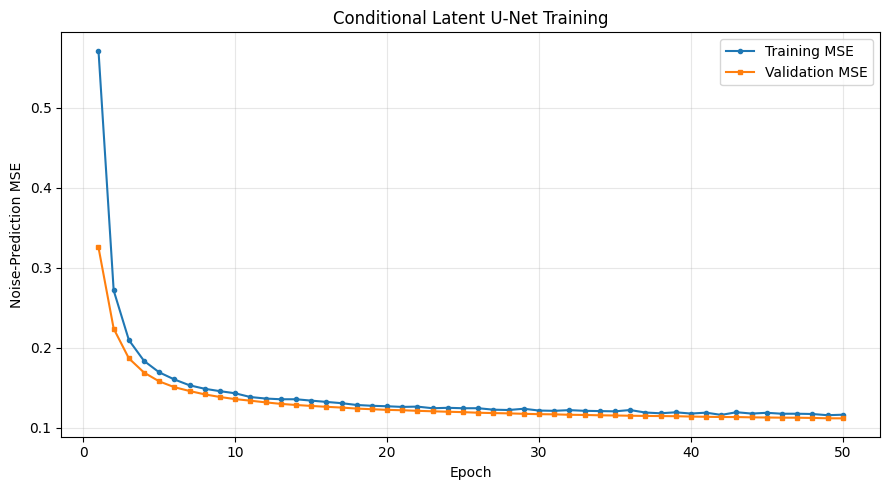

Loss figure saved to:
/content/drive/MyDrive/DATA266/HW9_1598/training_validation_loss.png


In [ ]:
epochs_axis = np.arange(
    1,
    len(training_losses) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_axis,
    training_losses,
    marker="o",
    markersize=3,
    label="Training MSE"
)

plt.plot(
    epochs_axis,
    validation_losses,
    marker="s",
    markersize=3,
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Noise-Prediction MSE")
plt.title("Conditional Latent U-Net Training")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

LOSS_FIGURE_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)

plt.savefig(
    LOSS_FIGURE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Loss figure saved to:")
print(LOSS_FIGURE_PATH)

Report training metrics

In [ ]:
best_validation_epoch = (
    int(np.argmin(validation_losses)) + 1
)

best_validation_loss = min(validation_losses)

print(f"Initial training loss: {training_losses[0]:.8f}")
print(f"Final training loss:   {training_losses[-1]:.8f}")
print(f"Initial validation loss: {validation_losses[0]:.8f}")
print(f"Final validation loss:   {validation_losses[-1]:.8f}")
print(f"Best validation loss:    {best_validation_loss:.8f}")
print(f"Best validation epoch:   {best_validation_epoch}")

assert np.isfinite(training_losses).all()
assert np.isfinite(validation_losses).all()

Initial training loss: 0.57163303
Final training loss:   0.11632118
Initial validation loss: 0.32552291
Final validation loss:   0.11176687
Best validation loss:    0.11176687
Best validation epoch:   50


## Task 4 Interpretation

The conditional latent U-Net was trained for 50 epochs using the Adam
optimizer, a learning rate of \(2\times10^{-5}\), and a batch size of 256.
The training target was the exact Gaussian noise used to construct each noisy
latent.

During training, each class label was independently replaced with null label
10 with probability 0.1. The observed label-drop rates remained close to 0.1,
including 0.0992 during the final epoch. This trained the same model to produce
both conditional and unconditional noise predictions, which are required for
classifier-free guidance.

The training MSE decreased from **0.57163303** in the first epoch to
**0.11632118** in the final epoch. The validation MSE decreased from
**0.32552291** to **0.11176687**. The best validation loss was
**0.11176687 at epoch 50**.

Both curves decreased sharply during the first few epochs and then improved
more gradually. Near the later epochs, the curves began to plateau around
0.11–0.12, although the validation loss continued to improve through epoch
50. The validation loss remained slightly lower than the training loss. This
is reasonable because training included classifier-free label dropout and
newly sampled noise and timesteps, making the training task more difficult,
while validation used complete class labels and a fixed noise experiment.

The small gap between the final training and validation losses does not
indicate overfitting. Instead, both curves remained close and continued
trending downward. The decreasing MSE indicates that the U-Net became much
better at estimating the Gaussian noise contained in noisy latent
representations.

Training took approximately **7.43 minutes** on the Tesla T4. The final model
checkpoint was saved as `hw9_sid1598_final.pt`. Although the loss curves show
successful noise-prediction learning, the final generated samples must still
be evaluated because a low MSE does not by itself guarantee recognizable or
class-consistent images.

# Task 5 — Classifier-Free Guided Sampling

Sampling begins with Gaussian noise in the VAE latent space. At every reverse
diffusion timestep, the U-Net produces:

1. A conditional noise prediction using the requested class label.
2. An unconditional prediction using null label 10.

The predictions are combined using the assignment's classifier-free guidance
formula:

\[
\epsilon_{\text{guided}}
=
(1+w)\epsilon_{\text{cond}}
-
w\epsilon_{\text{uncond}},
\qquad w=3.
\]

The guided prediction is used to move from \(z_t\) to \(z_{t-1}\). After all
1,000 reverse steps, the final latent is decoded by the pretrained VAE.

Reload and verify the final model

In [ ]:
assert os.path.exists(FINAL_CHECKPOINT_PATH), (
    f"Final checkpoint was not found at {FINAL_CHECKPOINT_PATH}"
)

sampling_checkpoint = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(
    sampling_checkpoint["model_state_dict"]
)

model = model.to(device)
model.eval()

print(
    "Loaded checkpoint from epoch:",
    sampling_checkpoint["epoch"] + 1
)

print(
    "Final saved training loss:",
    sampling_checkpoint["training_losses"][-1]
)

print(
    "Final saved validation loss:",
    sampling_checkpoint["validation_losses"][-1]
)

assert sampling_checkpoint["epoch"] + 1 == 50

Loaded checkpoint from epoch: 50
Final saved training loss: 0.11632118381261826
Final saved validation loss: 0.11176686877012253


Prepare the 64 requested labels

In [ ]:
NUMBER_OF_SAMPLES = 64
GUIDANCE_WEIGHT = 3.0

# Produces:
# 0, 1, 2, ..., 9, 0, 1, 2, ..., repeatedly.
target_labels = (
    torch.arange(
        NUMBER_OF_SAMPLES,
        device=device
    )
    % 10
).long()

null_labels = torch.full(
    (NUMBER_OF_SAMPLES,),
    NULL_LABEL,
    device=device,
    dtype=torch.long
)

print("Target labels:")
print(target_labels.cpu().tolist())

print("\nClass counts:")
for class_index in range(10):
    count = (
        target_labels == class_index
    ).sum().item()

    print(
        f"{class_index}: "
        f"{class_names[class_index]:<12} "
        f"{count} samples"
    )

assert target_labels.shape == (64,)
assert target_labels.min().item() == 0
assert target_labels.max().item() == 9

Target labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3]

Class counts:
0: T-shirt/top  7 samples
1: Trouser      7 samples
2: Pullover     7 samples
3: Dress        7 samples
4: Coat         6 samples
5: Sandal       6 samples
6: Shirt        6 samples
7: Sneaker      6 samples
8: Bag          6 samples
9: Ankle boot   6 samples


Reverse diffusion sampler

In [ ]:
@torch.no_grad()
def sample_with_classifier_free_guidance(
    model,
    class_labels,
    guidance_weight=3.0,
    sampling_seed=1598
):
    """
    Generate scaled VAE latents using DDPM reverse diffusion and
    classifier-free guidance.

    The conditional and unconditional batches are concatenated so
    both predictions can be calculated in one U-Net forward pass.
    """
    model.eval()

    number_of_samples = class_labels.shape[0]

    sampling_generator = torch.Generator(
        device=device
    )
    sampling_generator.manual_seed(
        sampling_seed
    )

    # z_T begins as standard Gaussian noise in the scaled latent space.
    z = torch.randn(
        (
            number_of_samples,
            4,
            8,
            8
        ),
        generator=sampling_generator,
        device=device,
        dtype=torch.float32
    )

    unconditional_labels = torch.full(
        (number_of_samples,),
        model.null_label,
        device=device,
        dtype=torch.long
    )

    # Save several stages for later visualization.
    snapshot_timesteps = {
        1000,
        800,
        600,
        400,
        200,
        0
    }

    snapshots = {
        1000: z.detach().cpu()
    }

    for timestep in tqdm(
        range(NUM_DIFFUSION_STEPS, 0, -1),
        total=NUM_DIFFUSION_STEPS,
        desc="Classifier-free sampling"
    ):
        t = torch.full(
            (number_of_samples,),
            timestep,
            device=device,
            dtype=torch.long
        )

        # One half is conditional; the other is unconditional.
        doubled_latents = torch.cat(
            [z, z],
            dim=0
        )

        doubled_timesteps = torch.cat(
            [t, t],
            dim=0
        )

        doubled_labels = torch.cat(
            [class_labels, unconditional_labels],
            dim=0
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            doubled_prediction = model(
                doubled_latents,
                doubled_timesteps,
                doubled_labels
            )

        doubled_prediction = doubled_prediction.float()

        epsilon_conditional, epsilon_unconditional = (
            doubled_prediction.chunk(2, dim=0)
        )

        # Use the exact equation provided in Homework 9.
        epsilon_guided = (
            (1.0 + guidance_weight)
            * epsilon_conditional
            - guidance_weight
            * epsilon_unconditional
        )

        alpha_t = alphas[timestep]
        beta_t = betas[timestep]
        alpha_bar_t = alpha_bars[timestep]
        alpha_bar_previous = alpha_bars[timestep - 1]

        # DDPM reverse-process mean:
        #
        # μ = 1/sqrt(alpha_t) *
        #     (z_t - beta_t/sqrt(1-alpha_bar_t) * epsilon)
        reverse_mean = (
            1.0 / torch.sqrt(alpha_t)
        ) * (
            z
            - (
                beta_t
                / torch.sqrt(1.0 - alpha_bar_t)
            )
            * epsilon_guided
        )

        if timestep > 1:
            # Posterior variance:
            # beta_tilde =
            # beta_t * (1-alpha_bar_previous)/(1-alpha_bar_t)
            posterior_variance = (
                beta_t
                * (1.0 - alpha_bar_previous)
                / (1.0 - alpha_bar_t)
            )

            reverse_noise = torch.randn(
                z.shape,
                generator=sampling_generator,
                device=device,
                dtype=z.dtype
            )

            z = (
                reverse_mean
                + torch.sqrt(posterior_variance)
                * reverse_noise
            )
        else:
            # No additional randomness after the final reverse step.
            z = reverse_mean

        resulting_timestep = timestep - 1

        if resulting_timestep in snapshot_timesteps:
            snapshots[resulting_timestep] = (
                z.detach().cpu()
            )

        if timestep % 100 == 0:
            if not torch.isfinite(z).all():
                raise RuntimeError(
                    f"Non-finite latent values appeared at t={timestep}."
                )

    return z, snapshots

Generate 64 latent samples

In [ ]:
generated_latents, sampling_snapshots = (
    sample_with_classifier_free_guidance(
        model=model,
        class_labels=target_labels,
        guidance_weight=GUIDANCE_WEIGHT,
        sampling_seed=SEED
    )
)

print("Generated latent shape:", generated_latents.shape)
print("Generated latent mean:", generated_latents.mean().item())
print("Generated latent std: ", generated_latents.std().item())
print(
    "Saved snapshot timesteps:",
    sorted(sampling_snapshots.keys(), reverse=True)
)

assert generated_latents.shape == (64, 4, 8, 8)
assert torch.isfinite(generated_latents).all()
assert set(sampling_snapshots.keys()) == {
    1000,
    800,
    600,
    400,
    200,
    0
}

Classifier-free sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

Generated latent shape: torch.Size([64, 4, 8, 8])
Generated latent mean: -0.043071448802948
Generated latent std:  1.108999490737915
Saved snapshot timesteps: [1000, 800, 600, 400, 200, 0]


Save generated latents

In [ ]:
GENERATED_LATENTS_PATH = os.path.join(
    OUTPUT_DIR,
    "generated_latents_cfg_w3_sid1598.pt"
)

torch.save(
    {
        "generated_latents": generated_latents.cpu(),
        "target_labels": target_labels.cpu(),
        "guidance_weight": GUIDANCE_WEIGHT,
        "sampling_seed": SEED,
        "snapshots": sampling_snapshots
    },
    GENERATED_LATENTS_PATH
)

print("Generated latents saved to:")
print(GENERATED_LATENTS_PATH)

Generated latents saved to:
/content/drive/MyDrive/DATA266/HW9_1598/generated_latents_cfg_w3_sid1598.pt


Move the VAE back to the GPU and decode

In [ ]:
vae = vae.to(device)
vae.eval()

decoded_batches = []

DECODE_BATCH_SIZE = 16

with torch.no_grad():
    for start_index in range(
        0,
        NUMBER_OF_SAMPLES,
        DECODE_BATCH_SIZE
    ):
        end_index = min(
            start_index + DECODE_BATCH_SIZE,
            NUMBER_OF_SAMPLES
        )

        latent_batch = generated_latents[
            start_index:end_index
        ]

        decoded_batch = vae.decode(
            latent_batch / LATENT_SCALE
        ).sample

        decoded_batches.append(
            decoded_batch.cpu()
        )

decoded_samples = torch.cat(
    decoded_batches,
    dim=0
)

display_samples = to_display_range(
    decoded_samples
)

print("Decoded sample shape:", decoded_samples.shape)
print(
    "Raw decoded range:",
    decoded_samples.min().item(),
    "to",
    decoded_samples.max().item()
)

assert decoded_samples.shape == (64, 3, 64, 64)
assert torch.isfinite(decoded_samples).all()

Decoded sample shape: torch.Size([64, 3, 64, 64])
Raw decoded range: -1.4895203113555908 to 1.1679373979568481


Required 64-image sample grid

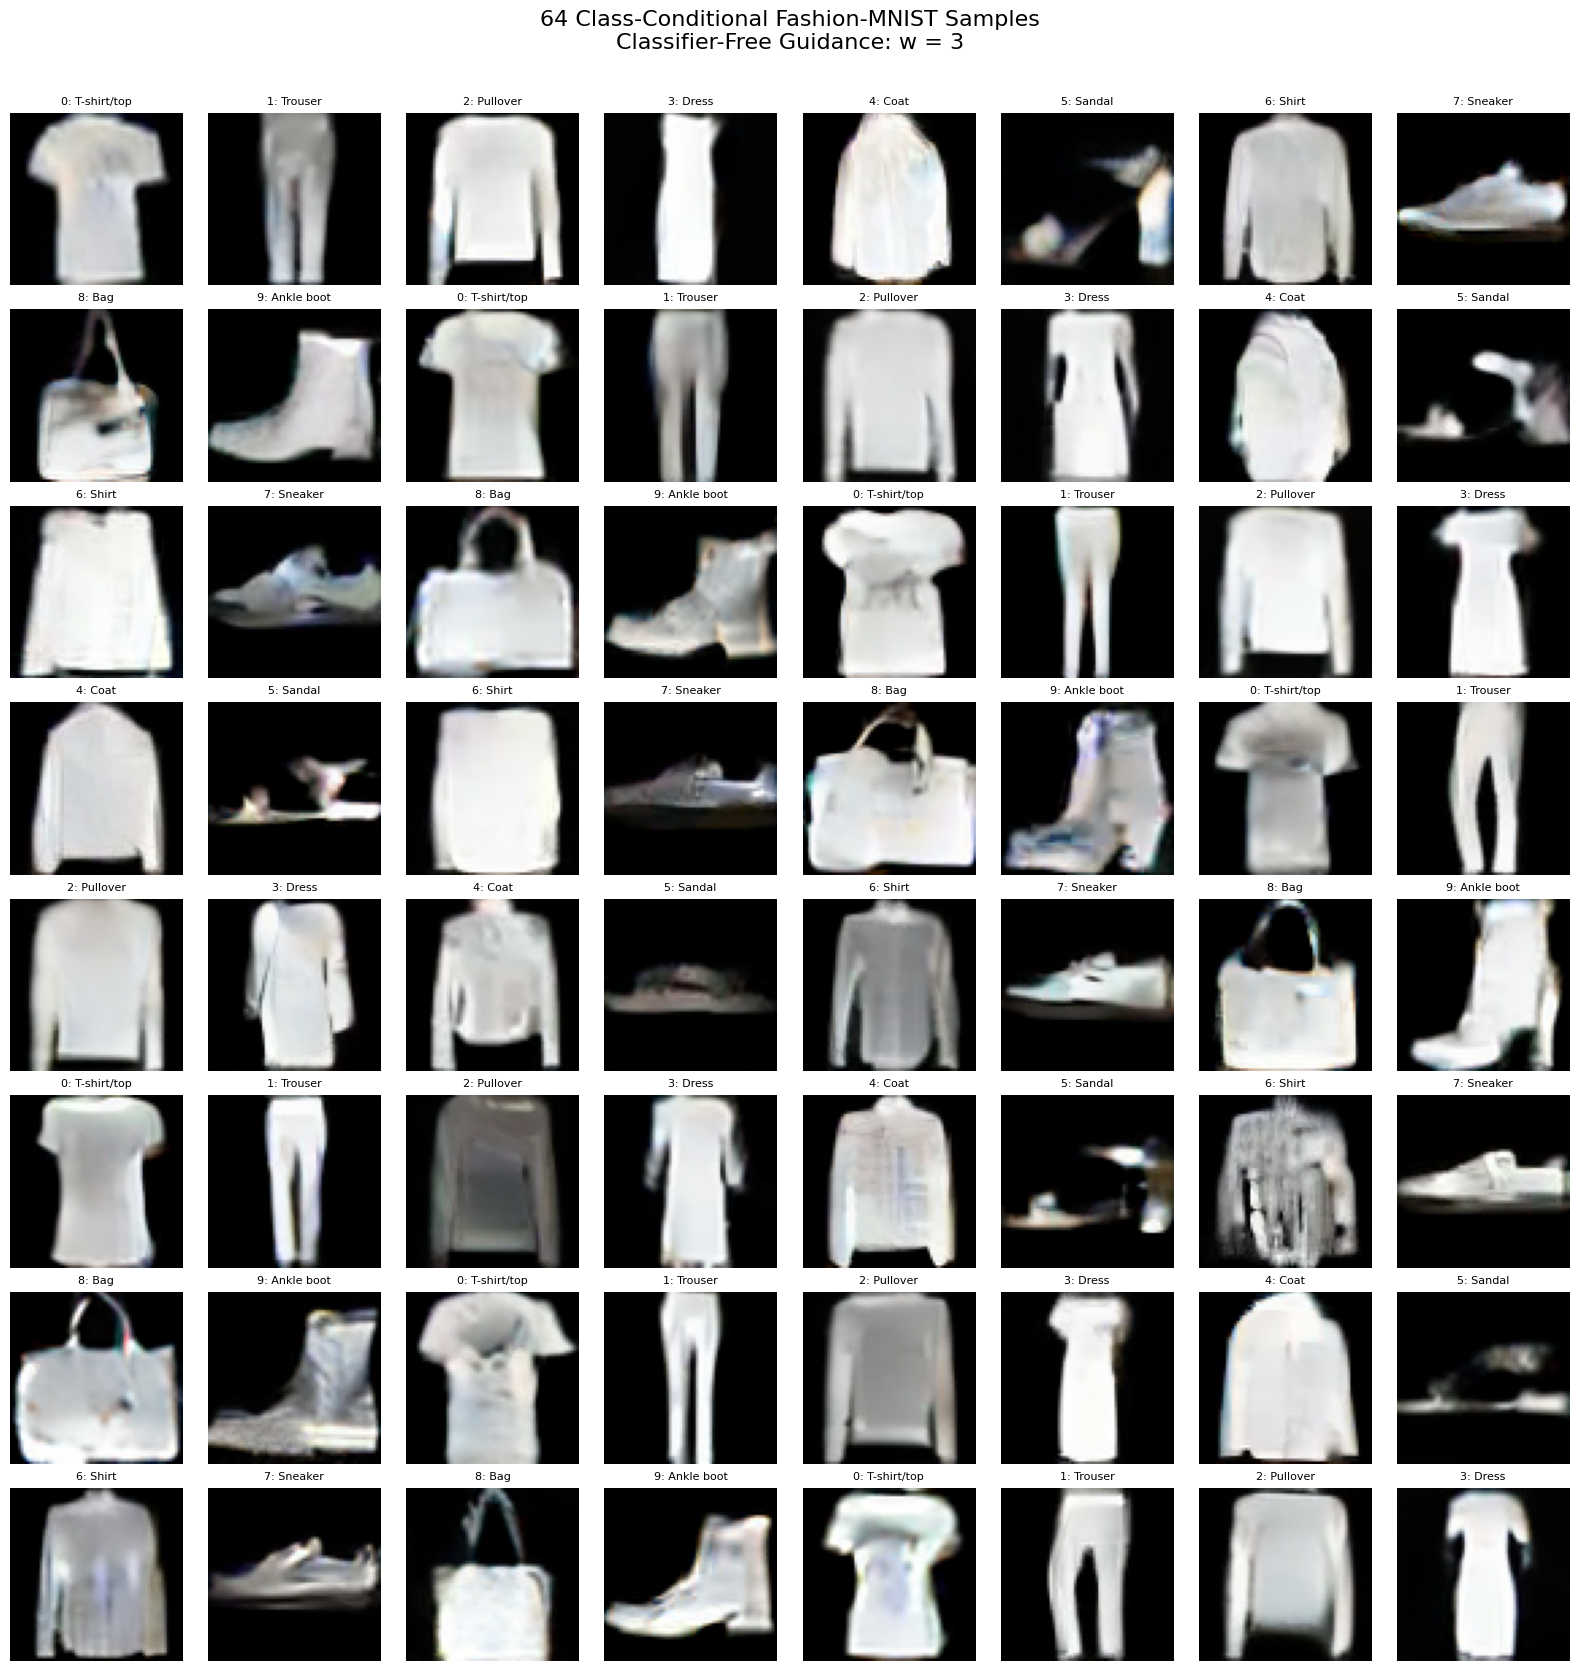

Sample grid saved to:
/content/drive/MyDrive/DATA266/HW9_1598/conditional_sample_grid_64_cfg_w3.png


In [ ]:
fig, axes = plt.subplots(
    8,
    8,
    figsize=(16, 17)
)

for sample_index, axis in enumerate(axes.flat):
    image = (
        display_samples[sample_index]
        .permute(1, 2, 0)
        .numpy()
    )

    label_index = target_labels[
        sample_index
    ].item()

    axis.imshow(image)

    axis.set_title(
        f"{label_index}: {class_names[label_index]}",
        fontsize=8
    )

    axis.axis("off")

plt.suptitle(
    "64 Class-Conditional Fashion-MNIST Samples\n"
    "Classifier-Free Guidance: w = 3",
    fontsize=16
)

plt.tight_layout(rect=(0, 0, 1, 0.97))

SAMPLE_GRID_PATH = os.path.join(
    OUTPUT_DIR,
    "conditional_sample_grid_64_cfg_w3.png"
)

plt.savefig(
    SAMPLE_GRID_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Sample grid saved to:")
print(SAMPLE_GRID_PATH)

Visualize the reverse process

In [ ]:
snapshot_order = [
    1000,
    800,
    600,
    400,
    200,
    0
]

NUMBER_OF_PROGRESS_EXAMPLES = 10

decoded_snapshots = {}

with torch.no_grad():
    for timestep in snapshot_order:
        snapshot_latents = (
            sampling_snapshots[timestep][
                :NUMBER_OF_PROGRESS_EXAMPLES
            ]
            .to(device)
        )

        decoded_snapshot = vae.decode(
            snapshot_latents / LATENT_SCALE
        ).sample

        decoded_snapshots[timestep] = (
            to_display_range(decoded_snapshot)
            .cpu()
        )

Plot them:

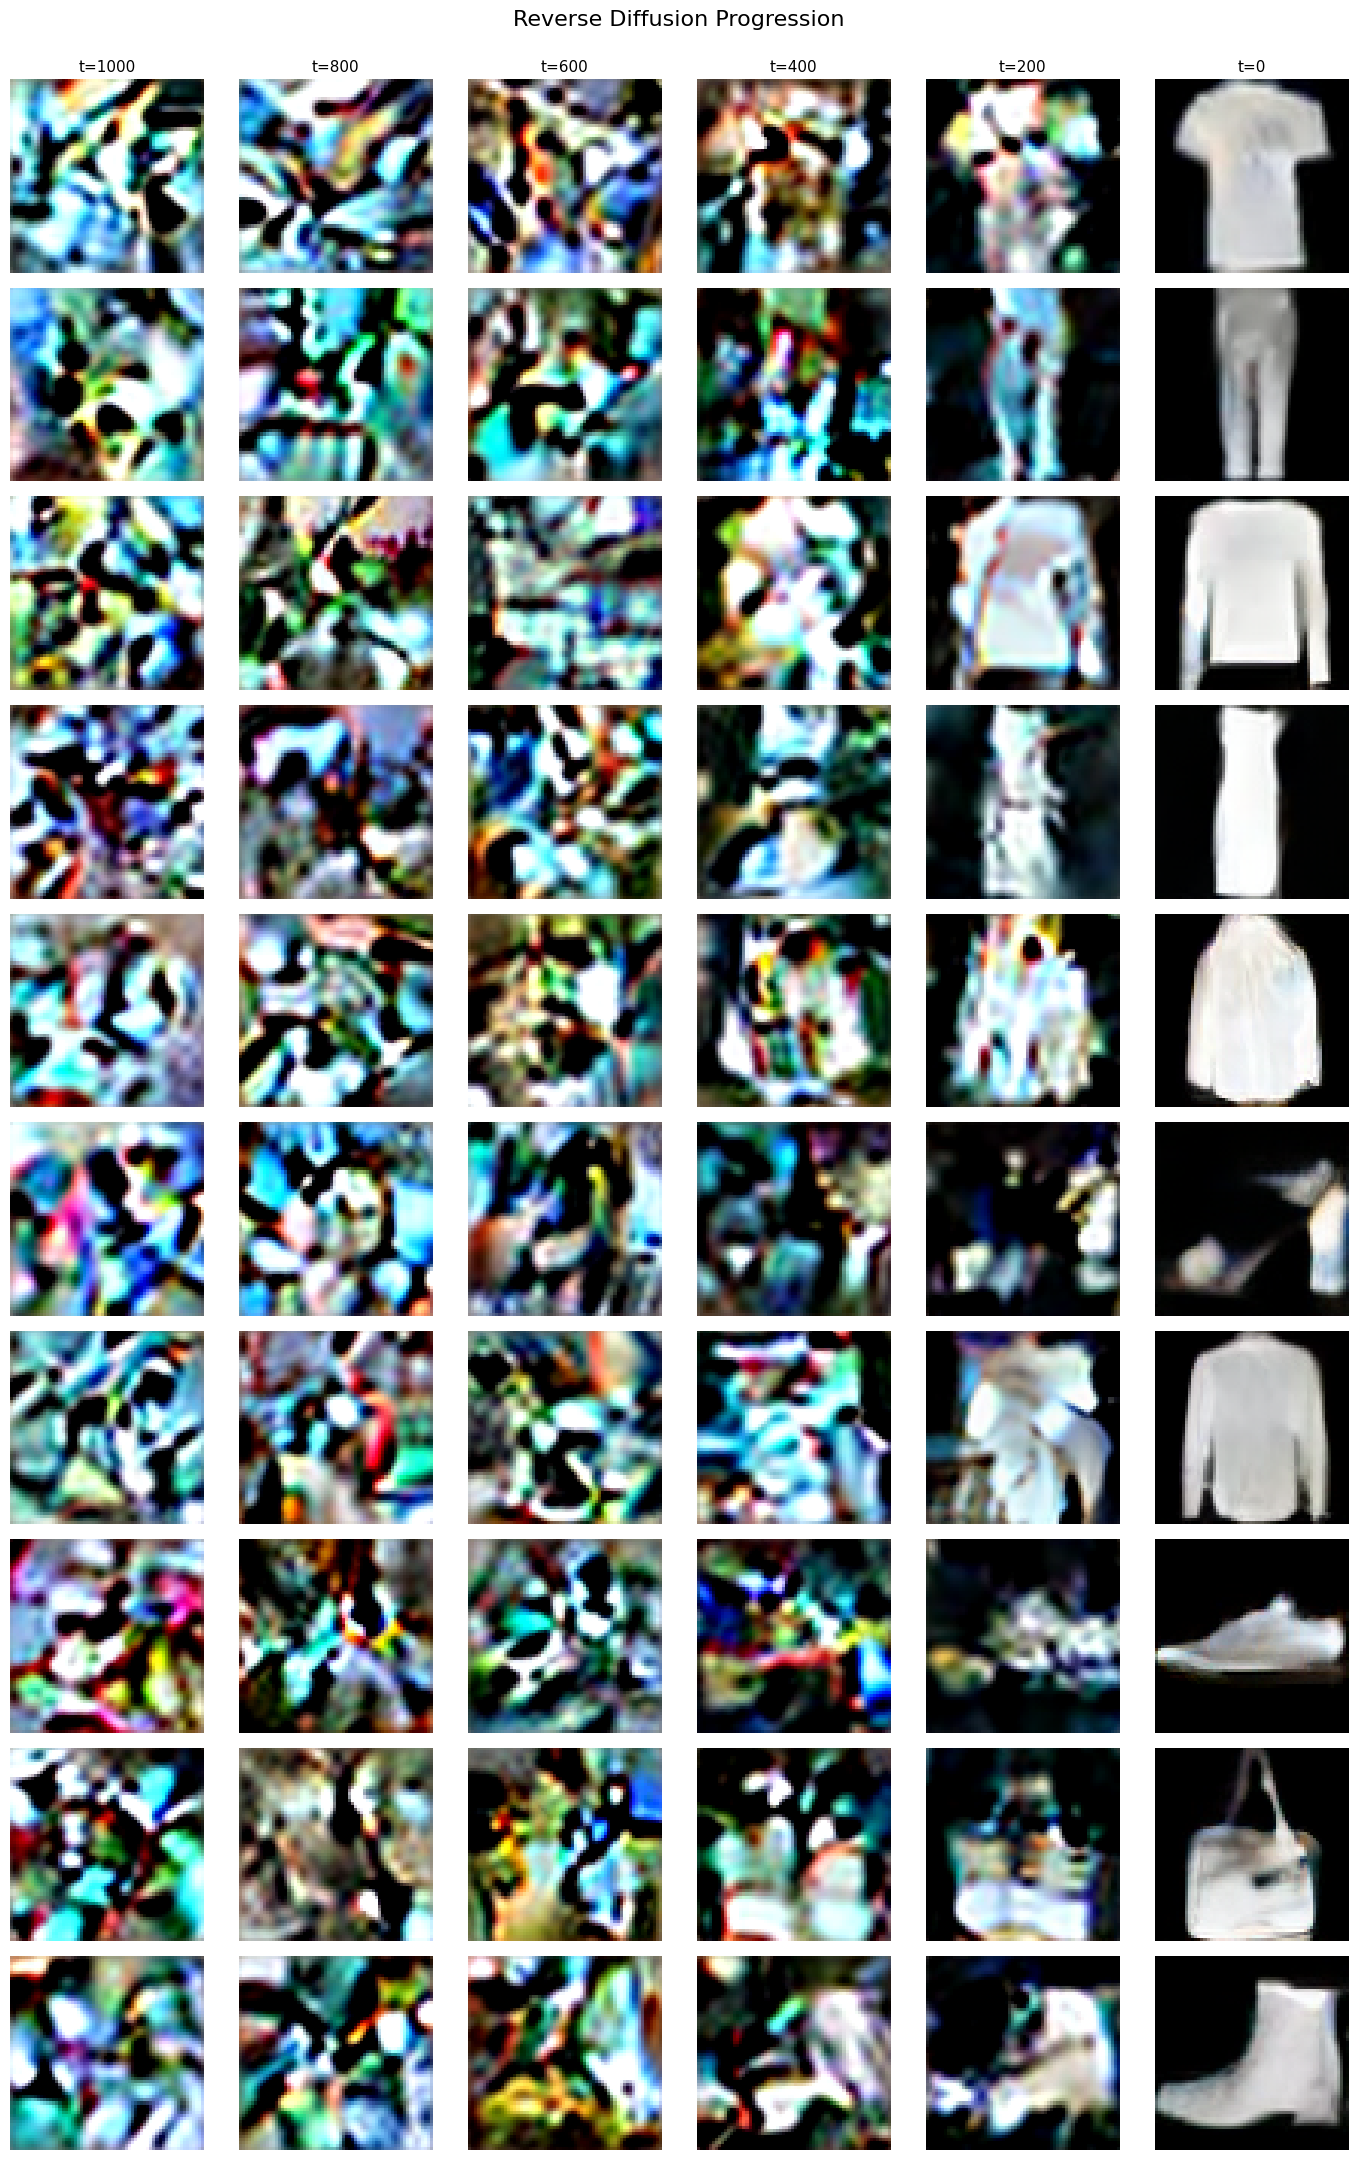

Progress figure saved to:
/content/drive/MyDrive/DATA266/HW9_1598/reverse_diffusion_progress_cfg_w3.png


In [ ]:
fig, axes = plt.subplots(
    NUMBER_OF_PROGRESS_EXAMPLES,
    len(snapshot_order),
    figsize=(14, 22)
)

for row_index in range(
    NUMBER_OF_PROGRESS_EXAMPLES
):
    requested_label = target_labels[
        row_index
    ].item()

    for column_index, timestep in enumerate(
        snapshot_order
    ):
        image = (
            decoded_snapshots[timestep][row_index]
            .permute(1, 2, 0)
            .numpy()
        )

        axis = axes[row_index, column_index]
        axis.imshow(image)
        axis.axis("off")

        if row_index == 0:
            axis.set_title(
                f"t={timestep}",
                fontsize=11
            )

        if column_index == 0:
            axis.set_ylabel(
                f"{requested_label}\n"
                f"{class_names[requested_label]}",
                fontsize=9
            )

plt.suptitle(
    "Reverse Diffusion Progression",
    fontsize=16
)

plt.tight_layout(rect=(0, 0, 1, 0.98))

SAMPLING_PROGRESS_PATH = os.path.join(
    OUTPUT_DIR,
    "reverse_diffusion_progress_cfg_w3.png"
)

plt.savefig(
    SAMPLING_PROGRESS_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Progress figure saved to:")
print(SAMPLING_PROGRESS_PATH)

Record sampling information

In [ ]:
print("Number of generated images:", NUMBER_OF_SAMPLES)
print("Guidance weight:", GUIDANCE_WEIGHT)
print("Sampling seed:", SEED)
print("Reverse diffusion steps:", NUM_DIFFUSION_STEPS)
print("Final latent shape:", tuple(generated_latents.shape))
print("Decoded image shape:", tuple(decoded_samples.shape))

print("\nSaved artifacts:")
print("1.", SAMPLE_GRID_PATH)
print("2.", SAMPLING_PROGRESS_PATH)
print("3.", GENERATED_LATENTS_PATH)
print("4.", FINAL_CHECKPOINT_PATH)

Number of generated images: 64
Guidance weight: 3.0
Sampling seed: 1598
Reverse diffusion steps: 1000
Final latent shape: (64, 4, 8, 8)
Decoded image shape: (64, 3, 64, 64)

Saved artifacts:
1. /content/drive/MyDrive/DATA266/HW9_1598/conditional_sample_grid_64_cfg_w3.png
2. /content/drive/MyDrive/DATA266/HW9_1598/reverse_diffusion_progress_cfg_w3.png
3. /content/drive/MyDrive/DATA266/HW9_1598/generated_latents_cfg_w3_sid1598.pt
4. /content/drive/MyDrive/DATA266/HW9_1598/hw9_sid1598_final.pt


## Task 5 Interpretation

I generated 64 images by starting with seeded Gaussian noise in the scaled VAE
latent space. At every reverse diffusion step, the model produced a
conditional noise estimate using the requested Fashion-MNIST label and an
unconditional noise estimate using null label 10.

I combined these predictions using the required classifier-free guidance
equation:

$$
\epsilon_{\text{guided}}
=
(1+3)\epsilon_{\text{conditional}}
-
3\epsilon_{\text{unconditional}}.
$$

This uses the assignment's required guidance weight \(w=3\). The final latent
batch had shape `64 × 4 × 8 × 8`. After all 1,000 reverse diffusion steps, the
pretrained VAE decoded the latents into images with shape
`64 × 3 × 64 × 64`.

The requested labels repeated Fashion-MNIST classes 0–9 across the 64 samples.
Because 64 is not divisible by 10, classes 0–3 appeared seven times each,
while classes 4–9 appeared six times each.

### Visual evaluation

- **Most recognizable classes:** Trousers and footwear classes were especially
  recognizable because their overall silhouettes are visually distinct. Several
  T-shirts and other upper-body garments also developed clear outlines.

- **Most difficult classes:** T-shirt/top, pullover, coat, and shirt were more
  difficult to distinguish from one another. These classes have similar
  upper-body silhouettes, so some generated samples could reasonably be
  interpreted as more than one of these categories.

- **Common artifacts or failures:** Some intermediate and final samples contained
  blurred boundaries, uneven garment shapes, bright color patches, and residual
  texture. The color artifacts are notable because Fashion-MNIST is grayscale.
  They can occur because the pretrained VAE works in three RGB channels and was
  originally trained on natural color images rather than Fashion-MNIST.

- **Variation within repeated classes:** Repeated samples showed changes in
  garment width, orientation, outline, texture, and color tint. This indicates
  that the model did not simply reproduce one identical image for every class.

- **Label adherence:** The samples generally followed broad class structure,
  particularly for trousers, shoes, and other classes with distinctive
  silhouettes. Label adherence was less certain among visually similar
  upper-body classes.

The reverse-process visualization demonstrates how generation developed over
time. At \(t=1000\), the decoded latents consisted mainly of colorful,
unstructured patterns. Broad shapes began appearing during the intermediate
steps. By \(t=200\), recognizable garment structure was forming, and at
\(t=0\), several samples had clear Fashion-MNIST silhouettes.

Classifier-free guidance strengthened class conditioning by amplifying the
difference between the conditional and unconditional noise predictions. This
helped the generated images move toward their requested classes while retaining
variation between repeated samples.

The final noise-prediction MSE was low, but the samples were not perfect. This
is expected because reverse diffusion required 1,000 consecutive predictions,
allowing small prediction errors to accumulate. In addition, the VAE was
pretrained on natural RGB images rather than Fashion-MNIST, which likely
contributed to color artifacts and softened boundaries.

In [ ]:
from datetime import datetime

METRICS_PATH = os.path.join(
    OUTPUT_DIR,
    "METRICS.md"
)

metrics_text = f"""# Homework 9 Metrics

## Personal Parameters

| Parameter | Value |
|---|---:|
| SID4 | {SID4} |
| SEED | {SEED} |
| SLICE | {SLICE} |
| HP_ID | {HP_ID} |
| CLS_A | {CLS_A} |
| CLS_B | {CLS_B} |

## Environment

| Item | Value |
|---|---|
| Platform | Google Colab |
| GPU | {torch.cuda.get_device_name(0)} |
| PyTorch | {torch.__version__} |
| VAE | {VAE_MODEL_ID} |
| VAE scaling factor | {LATENT_SCALE} |

## Task 1 — VAE Compression

| Metric | Value |
|---|---:|
| Input shape | 3 × 64 × 64 |
| Latent shape | 4 × 8 × 8 |
| Input values per image | {input_values_per_image} |
| Latent values per image | {latent_values_per_image} |
| Compression ratio | {compression_ratio:.1f}:1 |
| Mean reconstruction MSE, [-1, 1] | {mean_mse_normalized:.8f} |
| Std reconstruction MSE, [-1, 1] | {std_mse_normalized:.8f} |
| Mean reconstruction MSE, [0, 1] | {mean_mse_01:.8f} |
| Std reconstruction MSE, [0, 1] | {std_mse_01:.8f} |

## Task 2 — Forward Diffusion

| Timestep | Alpha bar | Signal coefficient | Noise coefficient |
|---:|---:|---:|---:|
| 0 | {alpha_bars[0].item():.8f} | {sqrt_alpha_bars[0].item():.8f} | {sqrt_one_minus_alpha_bars[0].item():.8f} |
| 200 | {alpha_bars[200].item():.8f} | {sqrt_alpha_bars[200].item():.8f} | {sqrt_one_minus_alpha_bars[200].item():.8f} |
| 500 | {alpha_bars[500].item():.8f} | {sqrt_alpha_bars[500].item():.8f} | {sqrt_one_minus_alpha_bars[500].item():.8f} |
| 800 | {alpha_bars[800].item():.8f} | {sqrt_alpha_bars[800].item():.8f} | {sqrt_one_minus_alpha_bars[800].item():.8f} |
| 1000 | {alpha_bars[1000].item():.8f} | {sqrt_alpha_bars[1000].item():.8f} | {sqrt_one_minus_alpha_bars[1000].item():.8f} |

## Task 4 — Training

| Metric | Value |
|---|---:|
| Epochs | {NUM_EPOCHS} |
| Learning rate | {LEARNING_RATE} |
| Batch size | {TRAIN_BATCH_SIZE} |
| Label-drop probability | {LABEL_DROP_PROBABILITY} |
| Initial training MSE | {training_losses[0]:.8f} |
| Final training MSE | {training_losses[-1]:.8f} |
| Initial validation MSE | {validation_losses[0]:.8f} |
| Final validation MSE | {validation_losses[-1]:.8f} |
| Best validation MSE | {best_validation_loss:.8f} |
| Best validation epoch | {best_validation_epoch} |
| Training time | {total_training_time / 60:.2f} minutes |

## Task 5 — Sampling

| Setting | Value |
|---|---:|
| Generated images | {NUMBER_OF_SAMPLES} |
| Guidance weight | {GUIDANCE_WEIGHT} |
| Reverse diffusion steps | {NUM_DIFFUSION_STEPS} |
| Sampling seed | {SEED} |
| Final latent shape | 64 × 4 × 8 × 8 |
| Decoded image shape | 64 × 3 × 64 × 64 |

Generation was evaluated qualitatively using the 64-image grid and reverse
diffusion progression. No classifier-based generation accuracy was computed.

## Saved Artifacts

- Final checkpoint: `{FINAL_CHECKPOINT_PATH}`
- Sample grid: `{SAMPLE_GRID_PATH}`
- Reverse-process figure: `{SAMPLING_PROGRESS_PATH}`
- Generated latents: `{GENERATED_LATENTS_PATH}`
- Training-loss figure: `{LOSS_FIGURE_PATH}`
"""

with open(METRICS_PATH, "w", encoding="utf-8") as file:
    file.write(metrics_text)

print(metrics_text)
print("\nSaved:", METRICS_PATH)

# Homework 9 Metrics

## Personal Parameters

| Parameter | Value |
|---|---:|
| SID4 | 1598 |
| SEED | 1598 |
| SLICE | 598 |
| HP_ID | 2 |
| CLS_A | 8 |
| CLS_B | 5 |

## Environment

| Item | Value |
|---|---|
| Platform | Google Colab |
| GPU | Tesla T4 |
| PyTorch | 2.11.0+cu130 |
| VAE | stabilityai/sd-vae-ft-mse |
| VAE scaling factor | 0.18215 |

## Task 1 — VAE Compression

| Metric | Value |
|---|---:|
| Input shape | 3 × 64 × 64 |
| Latent shape | 4 × 8 × 8 |
| Input values per image | 12288 |
| Latent values per image | 256 |
| Compression ratio | 48.0:1 |
| Mean reconstruction MSE, [-1, 1] | 0.00954555 |
| Std reconstruction MSE, [-1, 1] | 0.00622775 |
| Mean reconstruction MSE, [0, 1] | 0.00229053 |
| Std reconstruction MSE, [0, 1] | 0.00152609 |

## Task 2 — Forward Diffusion

| Timestep | Alpha bar | Signal coefficient | Noise coefficient |
|---:|---:|---:|---:|
| 0 | 1.00000000 | 1.00000000 | 0.00000000 |
| 200 | 0.65903884 | 0.81181204 | 0.58391881 |
| 500 | 0.0785872

In [ ]:
RUN_LOG_PATH = os.path.join(
    OUTPUT_DIR,
    "RUN_LOG.txt"
)

epoch_log_lines = []

for epoch_index, (train_loss, validation_loss) in enumerate(
    zip(training_losses, validation_losses),
    start=1
):
    epoch_log_lines.append(
        f"Epoch {epoch_index:02d}/{NUM_EPOCHS} | "
        f"train_mse={train_loss:.8f} | "
        f"validation_mse={validation_loss:.8f}"
    )

run_log_text = f"""Homework 9 Run Log
==================

Log generated: {datetime.now().astimezone().isoformat()}
Notebook: DATA266_HW9_1598.ipynb
SID4: {SID4}
Seed: {SEED}

Environment
-----------
Platform: Google Colab
GPU: {torch.cuda.get_device_name(0)}
PyTorch: {torch.__version__}
Device: {device}

Execution method
----------------
Google Colab menu: Runtime > Run all
Runtime type: T4 GPU

Training configuration
----------------------
Epochs: {NUM_EPOCHS}
Learning rate: {LEARNING_RATE}
Batch size: {TRAIN_BATCH_SIZE}
Diffusion steps: {NUM_DIFFUSION_STEPS}
Label-drop probability: {LABEL_DROP_PROBABILITY}
Target: Gaussian noise
Loss: Mean squared error
Optimizer: Adam
Mixed precision: enabled

Epoch results
-------------
{chr(10).join(epoch_log_lines)}

Final results
-------------
Initial training MSE: {training_losses[0]:.8f}
Final training MSE: {training_losses[-1]:.8f}
Initial validation MSE: {validation_losses[0]:.8f}
Final validation MSE: {validation_losses[-1]:.8f}
Best validation MSE: {best_validation_loss:.8f}
Best validation epoch: {best_validation_epoch}
Training-cell time: {total_training_time / 60:.2f} minutes

Sampling
--------
Generated images: {NUMBER_OF_SAMPLES}
Guidance weight: {GUIDANCE_WEIGHT}
Sampling seed: {SEED}
Reverse steps: {NUM_DIFFUSION_STEPS}
Final latent shape: {tuple(generated_latents.shape)}
Decoded image shape: {tuple(decoded_samples.shape)}

Errors
------
No runtime errors occurred during the completed 50-epoch training and
1,000-step sampling runs.

Artifacts
---------
{FINAL_CHECKPOINT_PATH}
{SAMPLE_GRID_PATH}
{SAMPLING_PROGRESS_PATH}
{GENERATED_LATENTS_PATH}
{LOSS_FIGURE_PATH}
"""

with open(RUN_LOG_PATH, "w", encoding="utf-8") as file:
    file.write(run_log_text)

print(run_log_text)
print("\nSaved:", RUN_LOG_PATH)

Homework 9 Run Log

Log generated: 2026-10-28T03:11:30.013902+00:00
Notebook: DATA266_HW9_1598.ipynb
SID4: 1598
Seed: 1598

Environment
-----------
Platform: Google Colab
GPU: Tesla T4
PyTorch: 2.11.0+cu130
Device: cuda

Execution method
----------------
Google Colab menu: Runtime > Run all
Runtime type: T4 GPU

Training configuration
----------------------
Epochs: 50
Learning rate: 2e-05
Batch size: 256
Diffusion steps: 1000
Label-drop probability: 0.1
Target: Gaussian noise
Loss: Mean squared error
Optimizer: Adam
Mixed precision: enabled

Epoch results
-------------
Epoch 01/50 | train_mse=0.57163303 | validation_mse=0.32552291
Epoch 02/50 | train_mse=0.27171973 | validation_mse=0.22397135
Epoch 03/50 | train_mse=0.20971074 | validation_mse=0.18679683
Epoch 04/50 | train_mse=0.18357097 | validation_mse=0.16900162
Epoch 05/50 | train_mse=0.16927544 | validation_mse=0.15797712
Epoch 06/50 | train_mse=0.16036741 | validation_mse=0.15071450
Epoch 07/50 | train_mse=0.15307324 | validatio

In [ ]:
from importlib.metadata import version

REQUIREMENTS_PATH = os.path.join(
    OUTPUT_DIR,
    "requirements.txt"
)

required_packages = [
    "torch",
    "torchvision",
    "diffusers",
    "transformers",
    "accelerate",
    "safetensors",
    "numpy",
    "matplotlib",
    "tqdm"
]

requirements_lines = []

for package in required_packages:
    try:
        requirements_lines.append(
            f"{package}=={version(package)}"
        )
    except Exception:
        requirements_lines.append(package)

requirements_text = "\n".join(requirements_lines) + "\n"

with open(REQUIREMENTS_PATH, "w", encoding="utf-8") as file:
    file.write(requirements_text)

print(requirements_text)
print("Saved:", REQUIREMENTS_PATH)

torch==2.11.0+cu130
torchvision==0.26.0+cu130
diffusers==0.42.1
transformers==5.21.0
accelerate==1.15.0
safetensors==0.8.0
numpy==2.1.3
matplotlib==3.10.0
tqdm==4.67.3

Saved: /content/drive/MyDrive/DATA266/HW9_1598/requirements.txt
